# Cotality Residential Property Trend & Valuation Demo: Multimodal AI & Foundation Models in BigQuery

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

> **Live Workshop Demonstration Scope Notice**: This notebook is authored for **live presenter-led technical demonstrations and hands-on sandbox exploration** in Google Cloud BigQuery Studio (Colab Enterprise) or Vertex AI Workbench (`Copyright 2026 Google LLC`, `SPDX-License-Identifier: Apache-2.0`). All property records, addresses, historical trends, and comparable sales generated in Step 2.2 are **100% synthetic educational data**, paired with **public-domain / CC0 real residential exterior photographs** from Wikimedia Commons. Before distributing modified code bundles externally, follow your organization's standard open-source release review guidelines.

---

## End-to-End Use Case Overview

Property data and analytics teams routinely combine **three core tables** alongside **real property exterior photographs** and **listing descriptions**:

| Asset | BigQuery Table / Cloud Storage Path | What It Contains | How BigQuery AI/ML Uses It |
| :--- | :--- | :--- | :--- |
| **Real Property Photos** | `gs://<BUCKET>/cotality_property_demo/images/*.jpg` | 6 real-world residential house exterior photographs (CC0 / Public Domain) | Referenced via `OBJ.MAKE_REF` & inspected with multimodal `AI.GENERATE` |
| **1. Properties** | `<DATASET>.properties` | 100 residential properties (`sqft`, `bedrooms`, `bathrooms`, `year_built`, `list_price_usd`, `listing_notes`, `gcs_image_uri`) | Screened with `AI.IF`, segmented with `AI.CLASSIFY`, and valued with `AI.PREDICT` |
| **2. Sold & Rent History** | `<DATASET>.sold_and_rent_history` | 72 months of historical `median_sold_price_usd` and `avg_monthly_rent_usd` across 5 US metros | Projected 12 months forward with `AI.FORECAST` (**TimesFM**) |
| **3. Property Comps** | `<DATASET>.property_comps` | 240 recently closed comparable sales & leases (`sold_price_usd`, `monthly_rent_usd`) | Used as zero-shot context in `AI.PREDICT` (**TabFM**, *Public Preview*) |
| **(Optional) Semantic Layer** | `gs://<BUCKET>/property_okf/` | **Open Knowledge Format (`OKF v0.2`)** Markdown + YAML bundle defining **Effective Gross Rental Yield (%)** | Grounds `AI.GENERATE` in governed business formulas and exclusions |

---

## BigQuery AI/ML Capabilities Demonstrated

1. **`OBJ.MAKE_REF` & `OBJ.FETCH_METADATA`**: Governed `ObjectRef` pointers linking rows in `properties` directly to real house `.jpg` files in Cloud Storage without moving image bytes out of SQL.
2. **`AI.GENERATE` (Multimodal + Structured Schema + Executive Synthesis)**: Extracts `architectural_style`, `exterior_condition`, and `curb_appeal_score` (`1–10`) from real property photos, optionally grounds KPI SQL via `property_okf`, and writes a 2-sentence valuation brief.
3. **`AI.IF`**: Evaluates free-text `listing_notes` into a native SQL `BOOL` (`is_move_in_ready`) with zero prompt-parsing boilerplate.
4. **`AI.CLASSIFY`**: Categorizes listings into governed residential buyer segments (`Turnkey Family Home`, `Luxury Residence`, `Fixer-Upper / Value-Add`, `Starter / Cozy Home`).
5. **`AI.FORECAST` (+ `AI.EVALUATE`)**: Zero-shot 12-month metro sold-price and rent projections powered by **TimesFM**.
6. **`AI.PREDICT` (+ `AI.EVALUATE`)** *(Public Preview)*: Zero-shot fair-market sold price and monthly rent comp valuation powered by **TabFM**—with **no `CREATE MODEL` training step**.
7. **(Optional) Open Knowledge Format (`OKF v0.2`) in Cloud Storage (`gs://<BUCKET>/property_okf/`)**: Portable Markdown + YAML semantic definitions for our 3 tables and **Effective Gross Rental Yield (%)** KPI.

> **🎙️ Presenter Opening Talk Track (60 sec)**
> *"In this live demo, we're keeping the data model super simple—just the three tables every property analytics team knows by heart: active **Properties**, monthly **Sold & Rent History**, and closed **Property Comps**, plus **real exterior house photos** in Cloud Storage. Historically, combining photo inspection, listing text screening, metro time-series forecasting, and comp valuation meant stitching together four separate Python and ML pipelines. Watch how we run the entire workflow end-to-end—including automated dataset and storage cleanup at the end—directly inside standard BigQuery SQL."*

---
## Step 1: Environment Setup & Authentication

### Step 1.1 — Install Required Python Packages
Run the cell below once if executing in a fresh Colab or Workbench runtime.

In [ ]:
# Copyright 2026 Google LLC
# SPDX-License-Identifier: Apache-2.0

# @title Install BigQuery, Cloud Storage, and visualization libraries { display-mode: "form" }
!pip install --quiet --upgrade google-cloud-bigquery google-cloud-storage db-dtypes pyyaml pandas matplotlib pillow
print("Packages installed and ready.")

### Step 1.2 — Configure Project Parameters, Authenticate & Initialize Dataset + Bucket

> **🎙️ Live Demo Talk Track**
> *"Here we configure our demo project, dataset (`cotality_property`), shared workshop bucket (`cotality-workshop`), and Cloud Resource Connection (`us.cotality-conn`). Using a Cloud Resource Connection lets BigQuery access Cloud Storage photos and Vertex AI foundation models under governed IAM delegation—while leaving `CONNECTION_ID` blank seamlessly falls back to end-user credentials in personal sandboxes."*

In [1]:
# Copyright 2026 Google LLC
# SPDX-License-Identifier: Apache-2.0

import io
import json
import os
import pathlib
import shutil
import sys
import time
import urllib.request

import google.auth
from google.cloud import bigquery
from google.cloud import storage
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from PIL import Image
import yaml

# @markdown ### Google Cloud Project & Demo Settings
PROJECT_ID = "cotality-proj"  # @param {type:"string"}
LOCATION = "US"  # @param {type:"string"}
DATASET_ID = "cotality_property"  # @param {type:"string"}
BUCKET_NAME = "cotality-workshop"  # @param {type:"string"}
CONNECTION_ID = "us.cotality-conn"  # @param {type:"string"}
AI_SAMPLE_LIMIT = 25  # @param {type:"integer"}

if not PROJECT_ID or PROJECT_ID == "your-gcp-project-id":
    detected_project = os.environ.get("GOOGLE_CLOUD_PROJECT", "")
    if detected_project:
        PROJECT_ID = detected_project
    else:
        raise ValueError("Please set PROJECT_ID in the form above before running.")

if not BUCKET_NAME:
    BUCKET_NAME = f"{PROJECT_ID}-cotality-simple-demo"

# Authenticate in public Google Colab; Colab Enterprise / Workbench use ambient ADC automatically
if "google.colab" in sys.modules and os.environ.get("VERTEX_PRODUCT") != "COLAB_ENTERPRISE":
    from google.colab import auth
    auth.authenticate_user()

credentials, _ = google.auth.default()
bq_client = bigquery.Client(project=PROJECT_ID, location=LOCATION, credentials=credentials)
storage_client = storage.Client(project=PROJECT_ID, credentials=credentials)

# Ensure BigQuery dataset exists
dataset_fqn = f"{PROJECT_ID}.{DATASET_ID}"
dataset_obj = bigquery.Dataset(dataset_fqn)
dataset_obj.location = LOCATION
dataset_obj.description = "Cotality simplified 3-table residential property AI/ML workshop dataset"
bq_client.create_dataset(dataset_obj, exists_ok=True)

# Ensure Cloud Storage bucket exists for real property photographs & optional OKF bundle
bucket = storage_client.bucket(BUCKET_NAME)
if not bucket.exists():
    bucket = storage_client.create_bucket(bucket, location=LOCATION)
    print(f"Created Cloud Storage bucket: gs://{BUCKET_NAME}")
else:
    print(f"Using existing Cloud Storage bucket: gs://{BUCKET_NAME}")

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#fafbfc",
    "axes.edgecolor": "#dadce0",
    "axes.grid": True,
    "grid.color": "#e8eaed",
    "grid.linestyle": "--",
    "font.size": 10,
})


def run_query(sql: str, label: str = "BigQuery SQL") -> pd.DataFrame:
    """Executes a BigQuery GoogleSQL query and prints runtime + processed bytes."""
    t0 = time.perf_counter()
    job = bq_client.query(sql)
    df = job.result().to_dataframe()
    elapsed = time.perf_counter() - t0
    mb_billed = (job.total_bytes_processed or 0) / (1024 * 1024)
    print(f"[{label}] {len(df):,} rows returned in {elapsed:.2f}s ({mb_billed:.2f} MB processed)")
    return df


print(f"Ready! Dataset: `{dataset_fqn}` | Bucket: `gs://{BUCKET_NAME}` | Connection: `{CONNECTION_ID or 'end-user'}`")

Using existing Cloud Storage bucket: gs://cotality-workshop
Ready! Dataset: `cotality-proj.cotality_property` | Bucket: `gs://cotality-workshop`


---
## Step 2: Stage Real Property Photographs & Create the 3 Core BigQuery Tables

### Step 2.1 — Pull 6 Real Residential Property Photographs & Upload to Cloud Storage
We stage **6 real-world residential exterior photographs** (100% Public Domain / CC0 from Wikimedia Commons) covering a contemporary custom home, a Mediterranean tile-roof residence, a Craftsman bungalow, an Austin wraparound-porch cottage, a sunny suburban ranch home, and a weathered fixer-upper.

If `./property_images/` is already present alongside the notebook, images load locally first; otherwise they download automatically over HTTPS and upload to `gs://<BUCKET>/cotality_property_demo/images/`.

> **🎙️ Live Demo Talk Track**
> *"Let's look at the actual residential photographs we're uploading to Cloud Storage. Notice the visual variety—from a contemporary stone-and-stucco residence and a Mediterranean barrel-tile roof home down to `PROP-106`, a weathered fixer-upper with peeling clapboard siding and worn roof shingles. None of those visual details exist in structured bedroom/bathroom columns yet—Gemini will read them directly from these `.jpg` files in Step 4."*

Uploaded PROP-101 -> gs://cotality-workshop/cotality_property_demo/images/prop_101_modern_custom_home.jpg (CC0 (Wikimedia Commons / Unsplash))
Uploaded PROP-102 -> gs://cotality-workshop/cotality_property_demo/images/prop_102_mediterranean_estate.jpg (Public Domain (Wikimedia Commons))
Uploaded PROP-103 -> gs://cotality-workshop/cotality_property_demo/images/prop_103_craftsman_bungalow.jpg (Public Domain (Wikimedia Commons))
Uploaded PROP-104 -> gs://cotality-workshop/cotality_property_demo/images/prop_104_austin_porch_cottage.jpg (Public Domain (Wikimedia Commons))
Uploaded PROP-105 -> gs://cotality-workshop/cotality_property_demo/images/prop_105_suburban_ranch_home.jpg (Public Domain (Wikimedia Commons))
Uploaded PROP-106 -> gs://cotality-workshop/cotality_property_demo/images/prop_106_distressed_fixer_upper.jpg (CC0 (Wikimedia Commons / Unsplash))


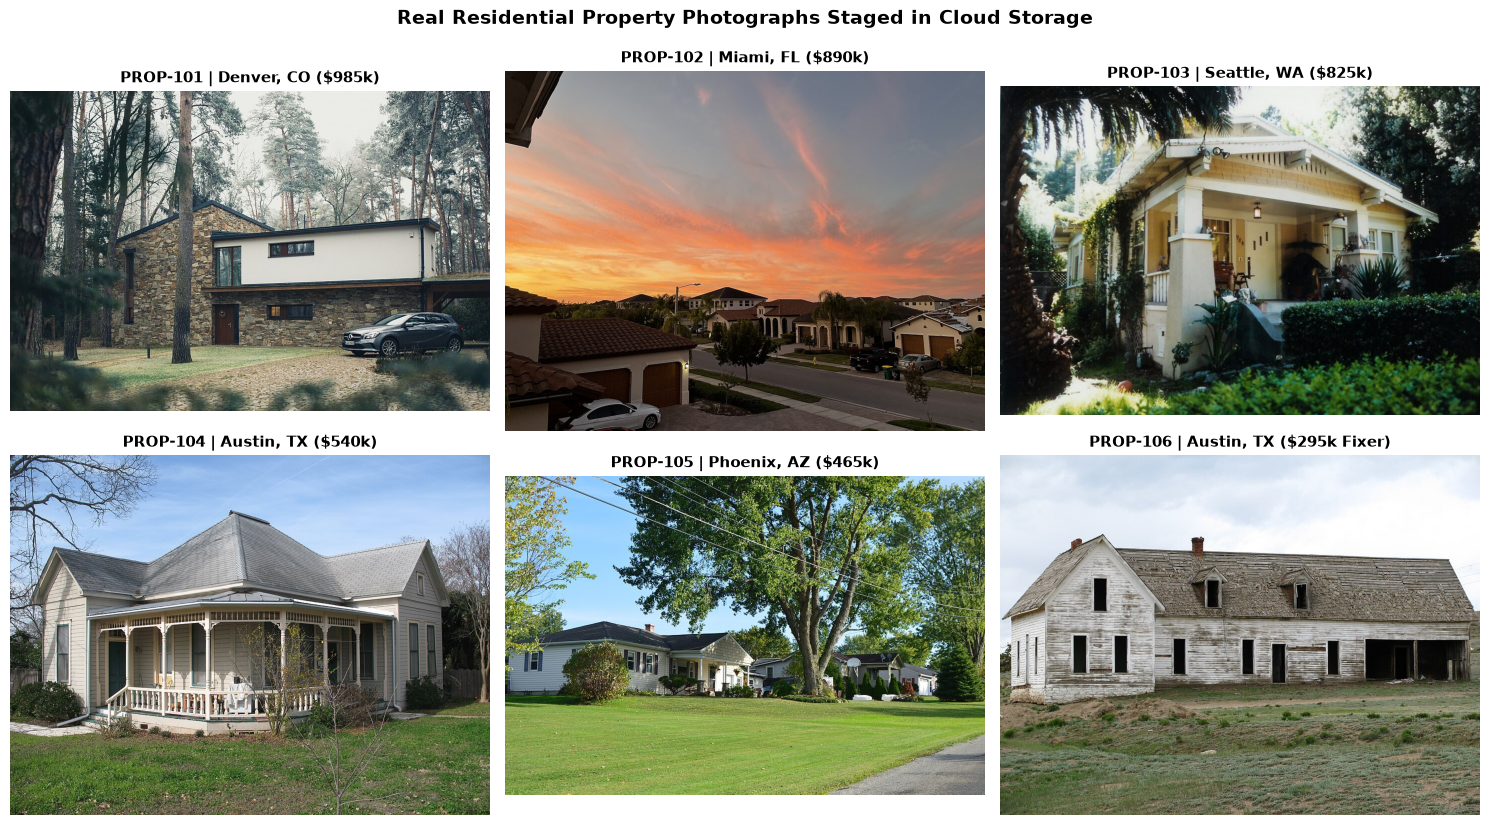

In [2]:
# Copyright 2026 Google LLC
# SPDX-License-Identifier: Apache-2.0

REAL_PROPERTY_PHOTOS = [
    {
        "property_id": "PROP-101",
        "filename": "prop_101_modern_custom_home.jpg",
        "label": "PROP-101 | Denver, CO ($985k)",
        "license": "CC0 (Wikimedia Commons / Unsplash)",
        "urls": [
            "https://thumb.wikimedia.org/wikipedia/commons/thumb/9/98/House_in_forest_%28Unsplash%29.jpg/960px-House_in_forest_%28Unsplash%29.jpg",
            "https://upload.wikimedia.org/wikipedia/commons/9/98/House_in_forest_%28Unsplash%29.jpg",
        ],
    },
    {
        "property_id": "PROP-102",
        "filename": "prop_102_mediterranean_estate.jpg",
        "label": "PROP-102 | Miami, FL ($890k)",
        "license": "Public Domain (Wikimedia Commons)",
        "urls": [
            "https://thumb.wikimedia.org/wikipedia/commons/thumb/9/9a/Ave_Maria_Sunset.jpg/960px-Ave_Maria_Sunset.jpg",
            "https://upload.wikimedia.org/wikipedia/commons/9/9a/Ave_Maria_Sunset.jpg",
        ],
    },
    {
        "property_id": "PROP-103",
        "filename": "prop_103_craftsman_bungalow.jpg",
        "label": "PROP-103 | Seattle, WA ($825k)",
        "license": "Public Domain (Wikimedia Commons)",
        "urls": [
            "https://thumb.wikimedia.org/wikipedia/commons/thumb/f/f0/Craftsman_Residential_House.jpg/960px-Craftsman_Residential_House.jpg",
            "https://upload.wikimedia.org/wikipedia/commons/f/f0/Craftsman_Residential_House.jpg",
        ],
    },
    {
        "property_id": "PROP-104",
        "filename": "prop_104_austin_porch_cottage.jpg",
        "label": "PROP-104 | Austin, TX ($515k)",
        "license": "Public Domain (Wikimedia Commons)",
        "urls": [
            "https://thumb.wikimedia.org/wikipedia/commons/thumb/b/b4/1170_San_Bernard.jpg/960px-1170_San_Bernard.jpg",
            "https://upload.wikimedia.org/wikipedia/commons/b/b4/1170_San_Bernard.jpg",
        ],
    },
    {
        "property_id": "PROP-105",
        "filename": "prop_105_suburban_ranch_home.jpg",
        "label": "PROP-105 | Phoenix, AZ ($465k)",
        "license": "Public Domain (Wikimedia Commons)",
        "urls": [
            "https://thumb.wikimedia.org/wikipedia/commons/thumb/1/18/Milton_south_of_Nora%2C_Clark.jpg/960px-Milton_south_of_Nora%2C_Clark.jpg",
            "https://upload.wikimedia.org/wikipedia/commons/1/18/Milton_south_of_Nora%2C_Clark.jpg",
        ],
    },
    {
        "property_id": "PROP-106",
        "filename": "prop_106_distressed_fixer_upper.jpg",
        "label": "PROP-106 | Austin, TX ($335k Fixer)",
        "license": "CC0 (Wikimedia Commons / Unsplash)",
        "urls": [
            "https://thumb.wikimedia.org/wikipedia/commons/thumb/6/61/Abandoned_rural_house_%28Unsplash%29.jpg/960px-Abandoned_rural_house_%28Unsplash%29.jpg",
            "https://upload.wikimedia.org/wikipedia/commons/6/61/Abandoned_rural_house_%28Unsplash%29.jpg",
        ],
    },
]

LOCAL_IMG_DIR = pathlib.Path("./property_images")
LOCAL_IMG_DIR.mkdir(parents=True, exist_ok=True)
HTTP_HEADERS = {"User-Agent": "CotalityBigQueryWorkshopDemo/1.0 (https://cloud.google.com/bigquery)"}

photo_gcs_uris: dict[str, str] = {}
loaded_images: list[tuple[str, Image.Image]] = []

for item in REAL_PROPERTY_PHOTOS:
    local_path = LOCAL_IMG_DIR / item["filename"]
    if not local_path.exists():
        last_err = None
        for url in item["urls"]:
            try:
                req = urllib.request.Request(url, headers=HTTP_HEADERS)
                with urllib.request.urlopen(req, timeout=25) as resp:
                    local_path.write_bytes(resp.read())
                break
            except Exception as err:  # pylint: disable=broad-except
                last_err = err
        if not local_path.exists():
            raise RuntimeError(f"Failed to download {item['filename']}: {last_err}")

    gcs_blob_path = f"cotality_property_demo/images/{item['filename']}"
    blob = bucket.blob(gcs_blob_path)
    blob.upload_from_filename(str(local_path), content_type="image/jpeg")
    gcs_uri = f"gs://{BUCKET_NAME}/{gcs_blob_path}"
    photo_gcs_uris[item["property_id"]] = gcs_uri
    loaded_images.append((item["label"], Image.open(io.BytesIO(local_path.read_bytes())).convert("RGB")))
    print(f"Uploaded {item['property_id']} -> {gcs_uri} ({item['license']})")

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (title_lbl, img_obj) in zip(axes.flat, loaded_images):
    ax.imshow(img_obj)
    ax.set_title(title_lbl, fontsize=10.5, fontweight="bold", pad=6)
    ax.axis("off")
plt.suptitle("Real Residential Property Photographs Staged in Cloud Storage", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

### Step 2.2 — Create the 3 Simple BigQuery Tables (`properties`, `sold_and_rent_history`, `property_comps`)

We materialize a clean, reproducible 3-table residential property dataset in BigQuery:
1. **`properties`** (`100` active properties, clustered by `metro_area, property_type`, with `PROP-101`..`PROP-106` linked to our 6 real property photos).
2. **`sold_and_rent_history`** (`360` monthly rows = `5` US metros × `72` months from `2020-01` to `2025-12`, partitioned by `month_date` and clustered by `metro_area`).
3. **`property_comps`** (`240` closed comparable sales and leases with verified `sold_price_usd` and `monthly_rent_usd` outcomes, split into `TRAIN` and `VALIDATION`).

> **🎙️ Live Demo Talk Track**
> *"Notice we apply BigQuery storage best practices right from creation: `sold_and_rent_history` is partitioned by `month_date` and clustered by `metro_area`, and `properties` and `property_comps` are clustered by `metro_area, property_type`. Let's also run `ML.DESCRIBE_DATA` to sanity-check our comparable sales distribution in one SQL statement."*

In [4]:
# Copyright 2026 Google LLC
# SPDX-License-Identifier: Apache-2.0

rng = np.random.default_rng(42)

METRO_PROFILES = {
    "Austin, TX": {"base_price": 515_000, "base_rent": 2_650, "annual_growth": 0.046},
    "Miami, FL": {"base_price": 640_000, "base_rent": 3_450, "annual_growth": 0.058},
    "Denver, CO": {"base_price": 590_000, "base_rent": 2_950, "annual_growth": 0.042},
    "Phoenix, AZ": {"base_price": 455_000, "base_rent": 2_350, "annual_growth": 0.044},
    "Seattle, WA": {"base_price": 760_000, "base_rent": 3_550, "annual_growth": 0.049},
}
TYPE_MULTIPLIERS = {"Single-Family": 1.00, "Townhome": 0.84, "Cottage": 0.78}


def price_and_rent_formula(
    metro: str,
    prop_type: str,
    sqft: int,
    beds: int,
    baths: float,
    year_built: int,
    pool_or_view: bool,
    fixer: bool,
    noise_scale: float = 0.035,
) -> tuple[float, float]:
    base_p = METRO_PROFILES[metro]["base_price"] * TYPE_MULTIPLIERS[prop_type]
    sqft_factor = (sqft / 2100.0) ** 0.78
    age_adj = 1.0 + np.clip((year_built - 1995) * 0.0022, -0.10, 0.08)
    amenity_adj = 1.12 if pool_or_view else 1.00
    condition_adj = 0.68 if fixer else 1.00
    sold_price = base_p * sqft_factor * age_adj * amenity_adj * condition_adj
    sold_price *= (1.0 + beds * 0.015 + baths * 0.02) * rng.normal(1.0, noise_scale)

    base_r = METRO_PROFILES[metro]["base_rent"] * TYPE_MULTIPLIERS[prop_type]
    monthly_rent = base_r * (sqft / 2100.0) ** 0.62 * (1.08 if pool_or_view else 1.0)
    monthly_rent *= (0.76 if fixer else 1.0) * rng.normal(1.0, noise_scale)
    return round(float(sold_price), -2), round(float(monthly_rent), -1)


# 1) Build `properties` (6 featured real-photo homes + 94 portfolio homes = 100 rows)
featured_rows = [
    {
        "property_id": "PROP-101",
        "address": "418 Pine Ridge Trail, Denver, CO",
        "metro_area": "Denver, CO",
        "property_type": "Single-Family",
        "sqft": 3450,
        "bedrooms": 4,
        "bathrooms": 3.5,
        "year_built": 2019,
        "has_pool_or_view": True,
        "list_price_usd": 985000.0,
        "current_monthly_rent_usd": 4950.0,
        "listing_notes": "Custom contemporary stone-and-stucco foothills residence with woodland views, timber carport, chef kitchen, and turnkey finishes.",
        "gcs_image_uri": photo_gcs_uris["PROP-101"],
    },
    {
        "property_id": "PROP-102",
        "address": "742 Palm Harbor Way, Miami, FL",
        "metro_area": "Miami, FL",
        "property_type": "Single-Family",
        "sqft": 3120,
        "bedrooms": 4,
        "bathrooms": 3.0,
        "year_built": 2021,
        "has_pool_or_view": True,
        "list_price_usd": 890000.0,
        "current_monthly_rent_usd": 4800.0,
        "listing_notes": "Upscale Mediterranean residence with barrel-tile roof, paver driveway, dual garage, resort patio, and impact windows in move-in-ready condition.",
        "gcs_image_uri": photo_gcs_uris["PROP-102"],
    },
    {
        "property_id": "PROP-103",
        "address": "964 Cedar Crest Ave, Seattle, WA",
        "metro_area": "Seattle, WA",
        "property_type": "Single-Family",
        "sqft": 2280,
        "bedrooms": 3,
        "bathrooms": 2.5,
        "year_built": 1998,
        "has_pool_or_view": False,
        "list_price_usd": 825000.0,
        "current_monthly_rent_usd": 3950.0,
        "listing_notes": "Well-maintained Craftsman single-family home featuring covered front porch with tapered columns, updated HVAC, and manicured landscaping.",
        "gcs_image_uri": photo_gcs_uris["PROP-103"],
    },
    {
        "property_id": "PROP-104",
        "address": "1170 San Bernard St, Austin, TX",
        "metro_area": "Austin, TX",
        "property_type": "Cottage",
        "sqft": 1780,
        "bedrooms": 3,
        "bathrooms": 2.0,
        "year_built": 1986,
        "has_pool_or_view": False,
        "list_price_usd": 515000.0,
        "current_monthly_rent_usd": 2720.0,
        "listing_notes": "Charming East Austin clapboard cottage with wraparound front porch, updated shingle roof, bright living room, and cozy starter-home layout.",
        "gcs_image_uri": photo_gcs_uris["PROP-104"],
    },
    {
        "property_id": "PROP-105",
        "address": "215 Meadowbrook Ln, Phoenix, AZ",
        "metro_area": "Phoenix, AZ",
        "property_type": "Single-Family",
        "sqft": 1960,
        "bedrooms": 3,
        "bathrooms": 2.0,
        "year_built": 1996,
        "has_pool_or_view": False,
        "list_price_usd": 465000.0,
        "current_monthly_rent_usd": 2480.0,
        "listing_notes": "Move-in-ready suburban single-story ranch home on spacious green lot with covered entry porch, updated kitchen appliances, and clean roof.",
        "gcs_image_uri": photo_gcs_uris["PROP-105"],
    },
    {
        "property_id": "PROP-106",
        "address": "809 Old Mill Rd, Austin, TX",
        "metro_area": "Austin, TX",
        "property_type": "Single-Family",
        "sqft": 2050,
        "bedrooms": 3,
        "bathrooms": 1.5,
        "year_built": 1962,
        "has_pool_or_view": False,
        "list_price_usd": 335000.0,
        "current_monthly_rent_usd": 1750.0,
        "listing_notes": "Investor as-is fixer-upper needing full roof shingle replacement, exterior wood siding repaint, window glazing, and interior rehab.",
        "gcs_image_uri": photo_gcs_uris["PROP-106"],
    },
]

NOTE_TEMPLATES = {
    "family": "Clean move-in-ready {beds}-bedroom suburban family home with updated kitchen, solid roof, and fenced backyard.",
    "luxury": "Custom luxury {beds}-bedroom residence featuring resort pool, scenic patio view, quartz counters, and designer finishes.",
    "starter": "Cozy {beds}-bedroom {ptype_low} ideal for first-time buyers with low-maintenance yard, fresh paint, and modern appliances.",
    "fixer": "Value-add {beds}-bedroom fixer-upper sold as-is; requires roof repair, exterior siding work, and kitchen/bath renovation.",
}

metros_list = list(METRO_PROFILES.keys())
ptypes_list = ["Single-Family", "Townhome", "Cottage"]
street_names = ["Oak", "Maple", "Sunset", "Canyon", "Lakeview", "Sycamore", "Highland", "Willow"]

extra_props = []
for idx in range(107, 201):
    metro = metros_list[idx % len(metros_list)]
    ptype = ptypes_list[0] if idx % 5 < 3 else (ptypes_list[1] if idx % 5 == 3 else ptypes_list[2])
    bucket_kind = ["family", "luxury", "starter", "fixer"][idx % 4]
    if bucket_kind == "luxury":
        ptype = "Single-Family"
        beds = int(rng.choice([4, 5]))
        baths = float(rng.choice([3.0, 3.5, 4.0]))
        sqft = int(rng.integers(2900, 4100))
        pool = True
        fixer = False
        yr = int(rng.integers(2012, 2024))
    elif bucket_kind == "starter":
        ptype = str(rng.choice(["Townhome", "Cottage"]))
        beds = int(rng.choice([2, 3]))
        baths = float(rng.choice([1.5, 2.0]))
        sqft = int(rng.integers(1250, 1750))
        pool = False
        fixer = False
        yr = int(rng.integers(1992, 2021))
    elif bucket_kind == "fixer":
        beds = int(rng.choice([3, 4]))
        baths = float(rng.choice([1.5, 2.0]))
        sqft = int(rng.integers(1650, 2450))
        pool = False
        fixer = True
        yr = int(rng.integers(1958, 1984))
    else:
        ptype = "Single-Family"
        beds = int(rng.choice([3, 4]))
        baths = float(rng.choice([2.0, 2.5, 3.0]))
        sqft = int(rng.integers(1950, 2850))
        pool = False
        fixer = False
        yr = int(rng.integers(1995, 2022))

    est_price, est_rent = price_and_rent_formula(metro, ptype, sqft, beds, baths, yr, pool, fixer, noise_scale=0.05)
    extra_props.append({
        "property_id": f"PROP-{idx}",
        "address": f"{100 + idx * 3} {street_names[idx % len(street_names)]} Dr, {metro}",
        "metro_area": metro,
        "property_type": ptype,
        "sqft": sqft,
        "bedrooms": beds,
        "bathrooms": baths,
        "year_built": yr,
        "has_pool_or_view": pool,
        "list_price_usd": est_price,
        "current_monthly_rent_usd": est_rent,
        "listing_notes": NOTE_TEMPLATES[bucket_kind].format(beds=beds, ptype_low=ptype.lower()),
        "gcs_image_uri": None,
    })

properties_df = pd.DataFrame(featured_rows + extra_props)

# 2) Build `sold_and_rent_history` (5 metros x 72 months = 360 rows)
months = pd.date_range("2020-01-01", "2025-12-01", freq="MS")
history_rows = []
for metro, prof in METRO_PROFILES.items():
    for m_idx, dt in enumerate(months):
        yr_frac = m_idx / 12.0
        growth = (1.0 + prof["annual_growth"]) ** yr_frac
        # Spring/summer housing seasonality
        season_price = 1.0 + 0.028 * np.sin(2 * np.pi * (dt.month - 3) / 12.0)
        season_rent = 1.0 + 0.018 * np.sin(2 * np.pi * (dt.month - 4) / 12.0)
        med_price = prof["base_price"] * 0.84 * growth * season_price * rng.normal(1.0, 0.008)
        avg_rent = prof["base_rent"] * 0.85 * ((1.0 + prof["annual_growth"] * 0.85) ** yr_frac) * season_rent * rng.normal(1.0, 0.007)
        sold_cnt = int(round(420 * season_price * rng.normal(1.0, 0.04)))
        history_rows.append({
            "month_date": dt.date(),
            "metro_area": metro,
            "median_sold_price_usd": round(float(med_price), 0),
            "avg_monthly_rent_usd": round(float(avg_rent), 0),
            "homes_sold_count": sold_cnt,
        })
history_df = pd.DataFrame(history_rows)

# 3) Build `property_comps` (240 closed sales & leases: 190 TRAIN, 50 VALIDATION)
comp_rows = []
for c_idx in range(1, 241):
    metro = metros_list[c_idx % len(metros_list)]
    ptype = ptypes_list[0] if c_idx % 5 < 3 else (ptypes_list[1] if c_idx % 5 == 3 else ptypes_list[2])
    fixer = bool(c_idx % 6 == 0)
    pool = bool((not fixer) and (c_idx % 4 == 0))
    beds = int(rng.choice([2, 3, 4, 5], p=[0.15, 0.45, 0.30, 0.10]))
    baths = float(rng.choice([1.5, 2.0, 2.5, 3.0, 3.5], p=[0.15, 0.35, 0.25, 0.15, 0.10]))
    sqft = int(np.clip(950 + beds * 420 + rng.normal(0, 220), 1150, 4200))
    yr = int(rng.integers(1960, 1985) if fixer else rng.integers(1985, 2024))
    sold_p, rent_m = price_and_rent_formula(metro, ptype, sqft, beds, baths, yr, pool, fixer, noise_scale=0.03)
    comp_rows.append({
        "comp_id": f"COMP-{1000 + c_idx}",
        "split_set": "TRAIN" if c_idx <= 190 else "VALIDATION",
        "metro_area": metro,
        "property_type": ptype,
        "sqft": sqft,
        "bedrooms": beds,
        "bathrooms": baths,
        "year_built": yr,
        "has_pool_or_view": pool,
        "is_fixer_upper": fixer,
        "sold_price_usd": sold_p,
        "monthly_rent_usd": rent_m,
    })
comps_df = pd.DataFrame(comp_rows)

# Load all 3 tables with Partitioning & Clustering
prop_job_cfg = bigquery.LoadJobConfig(
    write_disposition="WRITE_TRUNCATE",
    clustering_fields=["metro_area", "property_type"],
)
bq_client.load_table_from_dataframe(properties_df, f"{dataset_fqn}.properties", job_config=prop_job_cfg).result()

hist_job_cfg = bigquery.LoadJobConfig(
    write_disposition="WRITE_TRUNCATE",
    time_partitioning=bigquery.TimePartitioning(field="month_date", type_=bigquery.TimePartitioningType.MONTH),
    clustering_fields=["metro_area"],
)
bq_client.load_table_from_dataframe(history_df, f"{dataset_fqn}.sold_and_rent_history", job_config=hist_job_cfg).result()

comps_job_cfg = bigquery.LoadJobConfig(
    write_disposition="WRITE_TRUNCATE",
    clustering_fields=["metro_area", "property_type"],
)
bq_client.load_table_from_dataframe(comps_df, f"{dataset_fqn}.property_comps", job_config=comps_job_cfg).result()

print(
    f"Created 3 tables in `{dataset_fqn}`:\n"
    f"  1. properties            : {len(properties_df):,} rows (6 linked to real GCS photos)\n"
    f"  2. sold_and_rent_history : {len(history_df):,} rows (5 metros x 72 months)\n"
    f"  3. property_comps        : {len(comps_df):,} rows (190 TRAIN / 50 VALIDATION)"
)

# Sanity-check comparable sales features with ML.DESCRIBE_DATA
describe_df = run_query(
    f"""
    SELECT name, num_rows, num_nulls, min, max, median
    FROM ML.DESCRIBE_DATA(
      (SELECT sqft, bedrooms, bathrooms, year_built, sold_price_usd, monthly_rent_usd
       FROM `{dataset_fqn}.property_comps`)
    )
    """,
    label="ML.DESCRIBE_DATA(property_comps)",
)
display(describe_df)

Created 3 tables in `cotality-proj.cotality_property`:
  1. properties            : 100 rows (6 linked to real GCS photos)
  2. sold_and_rent_history : 360 rows (5 metros x 72 months)
  3. property_comps        : 240 rows (190 TRAIN / 50 VALIDATION)
[ML.DESCRIBE_DATA(property_comps)] 6 rows returned in 1.98s (0.01 MB processed)


,name,num_rows,num_nulls,min,max,median
0,bathrooms,240,0,1.5,3.5,2.0
1,bedrooms,240,0,2,5,3.0
2,monthly_rent_usd,240,0,1290,4750,2920.0
3,sold_price_usd,240,0,217400,1062300,663000.0
4,sqft,240,0,1320,3691,2387.0
5,year_built,240,0,1961,2023,1999.0


---
## (Optional) Step 3: Open Knowledge Format (`OKF v0.2`) Stored in Cloud Storage (`gs://<BUCKET>/property_okf/`)

> *Note: Step 3 (`Step 3.1` & `Step 3.2`) is **optional** and controlled by `RUN_OPTIONAL_OKF` below (`True` by default for an end-to-end run; uncheck to jump straight to Step 4).*

Even with a clean 3-table schema, an LLM cannot guess your organization's exact business rules for KPIs like **Effective Gross Rental Yield (%)** (for example: *Should distressed fixer-uppers be excluded? Should we apply a `5%` annual vacancy allowance?*).

We package those definitions in **Open Knowledge Format (`OKF v0.2`)** and upload the bundle directly to **`gs://<BUCKET>/property_okf/`** in Cloud Storage so notebooks, scheduled SQL pipelines, and BigQuery Knowledge Catalog workflows share one governed semantic source of truth.

### (Optional) Step 3.1 — Build, Validate & Upload `property_okf` to Cloud Storage

> **🎙️ Live Demo Talk Track (Optional Section)**
> *"Before jumping into multimodal AI, let's look at how we keep AI-generated metrics trustworthy. Here we generate a 12-file Open Knowledge Format (`OKF v0.2`) bundle defining our 3 tables and our **Effective Gross Rental Yield (%)** rule—excluding fixer-uppers and applying a `5%` vacancy factor—and store it centrally at `gs://cotality-workshop/property_okf/`."*

In [10]:
# Copyright 2026 Google LLC
# SPDX-License-Identifier: Apache-2.0

# @title (Optional) Build, Validate & Upload OKF v0.2 Bundle to gs://<BUCKET>/property_okf/ { display-mode: "form" }
RUN_OPTIONAL_OKF = True  # @param {type:"boolean"}

OKF_DIR = pathlib.Path("./property_okf")
OKF_GCS_PREFIX = "property_okf"

if not RUN_OPTIONAL_OKF:
    print("Skipping Optional Step 3.1 (RUN_OPTIONAL_OKF = False). Proceed directly to Step 4.")
else:
    bq_ds_uri = f"//bigquery.googleapis.com/projects/{PROJECT_ID}/datasets/{DATASET_ID}"
    gen_ts = "2026-10-30T21:45:00Z"
    ver_ts = "2026-10-30T21:46:00Z"
    stale_ts = "2027-12-31T00:00:00Z"

    okf_files = {
        "index.md": f"""---
okf_version: "0.2"
title: "Cotality Residential Property & Comps Knowledge Bundle"
description: "Simplified Open Knowledge Format (OKF v0.2) semantic layer covering properties, sold and rent history, comparable sales, and Gross Rental Yield."
---

# Cotality Property & Comps — Open Knowledge Format (OKF v0.2)

* [Datasets](datasets/) - Governed BigQuery dataset container.
* [Tables](tables/) - Core residential tables (`properties`, `sold_and_rent_history`, `property_comps`).
* [Metrics](metrics/) - Canonical Gross Rental Yield (%) metric definition.
* [Computations](computations/) - Attested BigQuery SQL query for Gross Rental Yield (%).
""",
        "log.md": """# Knowledge Bundle Change Log

## 2026-10-30

* Published simplified 3-table Open Knowledge Format (OKF v0.2) bundle to Cloud Storage (`property_okf/`) with `gross_rental_yield` KPI.
""",
        "datasets/index.md": f"# Datasets\n\n* [Cotality Property Dataset]({DATASET_ID}.md)\n",
        "tables/index.md": (
            "# Tables\n\n"
            "* [Properties](properties.md)\n"
            "* [Sold and Rent History](sold_and_rent_history.md)\n"
            "* [Property Comps](property_comps.md)\n"
        ),
        "metrics/index.md": "# Metrics\n\n* [Gross Rental Yield](gross_rental_yield.md)\n",
        "computations/index.md": "# Attested Computations\n\n* [Gross Rental Yield SQL](gross_rental_yield_sql.md)\n",
        f"datasets/{DATASET_ID}.md": f"""---
type: "BigQuery Dataset"
title: "Cotality Property Dataset"
description: "Streamlined 3-table BigQuery dataset for residential property photo inspection, sold/rent forecasting, and comparable home valuation."
resource: "{bq_ds_uri}"
tags: ["cotality", "real-estate", "bigquery"]
status: "stable"
stale_after: "{stale_ts}"
generated:
  by: "cotality-okf-generator/0.2"
  at: "{gen_ts}"
verified:
  - by: "human:cotality_data_steward"
    at: "{ver_ts}"
sources:
  - id: "bq-schemata"
    resource: "{bq_ds_uri}/INFORMATION_SCHEMA.SCHEMATA"
    title: "BigQuery Dataset Metadata"
    author: "process:bigquery_information_schema"
    last_modified: "{gen_ts}"
---

# Cotality Property Dataset (`{DATASET_ID}`)

Unifies [Properties](../tables/properties.md), [Sold and Rent History](../tables/sold_and_rent_history.md), and [Property Comps](../tables/property_comps.md) [^bq-schemata].
""",
        "tables/properties.md": f"""---
type: "BigQuery Table"
title: "Properties"
description: "Active residential properties with physical attributes, listing_notes, and Cloud Storage exterior photo URIs."
resource: "{bq_ds_uri}/tables/properties"
tags: ["cotality", "properties", "objectref"]
status: "stable"
stale_after: "{stale_ts}"
generated:
  by: "cotality-okf-generator/0.2"
  at: "{gen_ts}"
verified:
  - by: "human:cotality_data_steward"
    at: "{ver_ts}"
sources:
  - id: "prop-cols"
    resource: "{bq_ds_uri}/INFORMATION_SCHEMA.COLUMNS"
    title: "INFORMATION_SCHEMA.COLUMNS for properties"
    author: "process:bigquery_information_schema"
    last_modified: "{gen_ts}"
---

# Properties (`properties`)

One row per residential property (`property_id`, `metro_area`, `property_type`, `sqft`, `bedrooms`, `bathrooms`, `year_built`, `has_pool_or_view`, `list_price_usd`, `current_monthly_rent_usd`, `listing_notes`, `gcs_image_uri`) [^prop-cols].
""",
        "tables/sold_and_rent_history.md": f"""---
type: "BigQuery Table"
title: "Sold and Rent History"
description: "Monthly historical median_sold_price_usd and avg_monthly_rent_usd across 5 US metros."
resource: "{bq_ds_uri}/tables/sold_and_rent_history"
tags: ["cotality", "history", "timesfm"]
status: "stable"
stale_after: "{stale_ts}"
generated:
  by: "cotality-okf-generator/0.2"
  at: "{gen_ts}"
verified:
  - by: "human:cotality_data_steward"
    at: "{ver_ts}"
sources:
  - id: "hist-cols"
    resource: "{bq_ds_uri}/INFORMATION_SCHEMA.COLUMNS"
    title: "INFORMATION_SCHEMA.COLUMNS for sold_and_rent_history"
    author: "process:bigquery_information_schema"
    last_modified: "{gen_ts}"
---

# Sold and Rent History (`sold_and_rent_history`)

Partitioned by `month_date` and clustered by `metro_area` for zero-shot `AI.FORECAST` projections [^hist-cols].
""",
        "tables/property_comps.md": f"""---
type: "BigQuery Table"
title: "Property Comps"
description: "Comparable sold and leased residential properties with sold_price_usd and monthly_rent_usd outcomes."
resource: "{bq_ds_uri}/tables/property_comps"
tags: ["cotality", "comps", "tabfm"]
status: "stable"
stale_after: "{stale_ts}"
generated:
  by: "cotality-okf-generator/0.2"
  at: "{gen_ts}"
verified:
  - by: "human:cotality_data_steward"
    at: "{ver_ts}"
sources:
  - id: "comps-cols"
    resource: "{bq_ds_uri}/INFORMATION_SCHEMA.COLUMNS"
    title: "INFORMATION_SCHEMA.COLUMNS for property_comps"
    author: "process:bigquery_information_schema"
    last_modified: "{gen_ts}"
---

# Property Comps (`property_comps`)

Closed residential sales and leases (`TRAIN` and `VALIDATION`) powering zero-shot `AI.PREDICT` valuation [^comps-cols].
""",
        "metrics/gross_rental_yield.md": f"""---
type: "Metric"
title: "Gross Rental Yield"
description: "Effective annualized rental yield (%) on move-in-ready residential homes after a 5% vacancy allowance."
resource: "{bq_ds_uri}/metrics/gross_rental_yield"
tags: ["cotality", "kpi", "rental-yield"]
status: "stable"
stale_after: "{stale_ts}"
generated:
  by: "cotality-okf-generator/0.2"
  at: "{gen_ts}"
verified:
  - by: "human:cotality_data_steward"
    at: "{ver_ts}"
sources:
  - id: "yield-guide"
    resource: "https://github.com/GoogleCloudPlatform/open-knowledge-format"
    title: "Cotality Residential Valuation & Yield Guide"
    author: "human:cotality_analytics_team"
    last_modified: "{gen_ts}"
---

# Effective Gross Rental Yield (%)

* **Formula**: `ROUND(100.0 * SAFE_DIVIDE(SUM(12.0 * monthly_rent_usd * 0.95), SUM(sold_price_usd)), 2)`
* **Governance Rule**: Include only move-in-ready residential homes (`is_fixer_upper = FALSE`) and apply a `0.95` effective collection factor (`5%` annual vacancy allowance) [^yield-guide].
* **Attested SQL**: See [Gross Rental Yield SQL](../computations/gross_rental_yield_sql.md).
""",
        "computations/gross_rental_yield_sql.md": f"""---
type: "Attested Computation"
title: "Gross Rental Yield SQL"
description: "Verified BigQuery GoogleSQL query computing Effective Gross Rental Yield (%) by metro_area."
resource: "{bq_ds_uri}/computations/gross_rental_yield_sql"
runtime: "bigquery"
tags: ["cotality", "attested-sql", "yield"]
status: "stable"
stale_after: "{stale_ts}"
generated:
  by: "cotality-okf-generator/0.2"
  at: "{gen_ts}"
verified:
  - by: "human:cotality_data_steward"
    at: "{ver_ts}"
sources:
  - id: "yield-spec"
    resource: "{bq_ds_uri}/metrics/gross_rental_yield"
    title: "Gross Rental Yield Metric Definition"
    author: "human:cotality_analytics_team"
    last_modified: "{gen_ts}"
---

# Gross Rental Yield SQL

Implements [Gross Rental Yield](../metrics/gross_rental_yield.md) across [Property Comps](../tables/property_comps.md) [^yield-spec].

```sql
SELECT
  metro_area,
  COUNT(*) AS move_in_ready_comps,
  ROUND(AVG(sold_price_usd), 0) AS avg_sold_price_usd,
  ROUND(AVG(monthly_rent_usd), 0) AS avg_monthly_rent_usd,
  ROUND(
    100.0 * SAFE_DIVIDE(SUM(12.0 * monthly_rent_usd * 0.95), SUM(sold_price_usd)),
    2
  ) AS effective_gross_rental_yield_pct
FROM `{dataset_fqn}.property_comps`
WHERE is_fixer_upper = FALSE
GROUP BY metro_area
ORDER BY effective_gross_rental_yield_pct DESC;
```
""",
    }

    errors = []
    for rel_path, text in okf_files.items():
        dest = OKF_DIR / rel_path
        dest.parent.mkdir(parents=True, exist_ok=True)
        dest.write_text(text, encoding="utf-8")
        if rel_path.endswith("index.md") and "/" in rel_path:
            if text.startswith("---"):
                errors.append(f"{rel_path}: subdirectory index must not have YAML frontmatter")
        elif rel_path != "log.md":
            parts = text.split("---", 2)
            meta = yaml.safe_load(parts[1])
            if rel_path == "index.md" and meta.get("okf_version") != "0.2":
                errors.append("Root index.md missing okf_version 0.2")
            elif rel_path != "index.md":
                for req in ("type", "title", "description", "resource", "generated", "sources"):
                    if req not in meta:
                        errors.append(f"{rel_path}: missing required OKF field '{req}'")

        # Upload each OKF file to gs://<BUCKET_NAME>/property_okf/<rel_path>
        gcs_okf_blob = bucket.blob(f"{OKF_GCS_PREFIX}/{rel_path}")
        gcs_okf_blob.upload_from_string(text, content_type="text/markdown; charset=utf-8")

    print(
        f"Validated & uploaded {len(okf_files)} OKF v0.2 files to `gs://{BUCKET_NAME}/{OKF_GCS_PREFIX}/` "
        f"(local mirror: `{OKF_DIR}`) | Validation errors: {len(errors)}"
    )
    if errors:
        print("\n".join(errors))

    # Execute the Attested SQL computation directly against `property_comps`
    attested_yield_df = run_query(
        f"""
        SELECT
          metro_area,
          COUNT(*) AS move_in_ready_comps,
          ROUND(AVG(sold_price_usd), 0) AS avg_sold_price_usd,
          ROUND(AVG(monthly_rent_usd), 0) AS avg_monthly_rent_usd,
          ROUND(
            100.0 * SAFE_DIVIDE(SUM(12.0 * monthly_rent_usd * 0.95), SUM(sold_price_usd)),
            2
          ) AS effective_gross_rental_yield_pct
        FROM `{dataset_fqn}.property_comps`
        WHERE is_fixer_upper = FALSE
        GROUP BY metro_area
        ORDER BY effective_gross_rental_yield_pct DESC
        """,
        label="Attested OKF Computation",
    )
    display(attested_yield_df)

Wrote 12 OKF v0.2 files to `cotality_simple_property_okf` | Validation errors: 0
OKF_DIR = 'cotality_simple_property_okf'
[Attested OKF Computation] 5 rows returned in 1.83s (0.00 MB processed)


,metro_area,move_in_ready_comps,avg_sold_price_usd,avg_monthly_rent_usd,effective_gross_rental_yield_pct
0,"Miami, FL",40,789685.0,3690.0,5.33
1,"Austin, TX",40,645215.0,2907.0,5.14
2,"Phoenix, AZ",40,494907.0,2199.0,5.06
3,"Denver, CO",40,748220.0,3246.0,4.95
4,"Seattle, WA",40,739303.0,3025.0,4.66


### (Optional) Step 3.2 — Ungrounded vs. OKF-Grounded `AI.GENERATE` (Loaded from `gs://<BUCKET>/property_okf/`)

> **🎙️ Live Demo Talk Track (Optional Section)**
> *"Watch what happens when we ask Gemini in BigQuery (`AI.GENERATE`) for **Effective Gross Rental Yield by metro** with column names alone versus reading our governed `property_okf` specification directly from Cloud Storage. Without OKF, the model writes a naive `12 * rent / price` across distressed fixer-uppers and misses the `5%` vacancy allowance. Grounded in `gs://cotality-workshop/property_okf/`, it generates the exact attested BigQuery SQL."*

In [24]:
# Copyright 2026 Google LLC
# SPDX-License-Identifier: Apache-2.0

if not globals().get("RUN_OPTIONAL_OKF", True):
    print("Skipping Optional Step 3.2 (RUN_OPTIONAL_OKF = False).")
else:
    # Read governed OKF metric & computation files directly from gs://<BUCKET>/property_okf/
    metric_md = bucket.blob(f"{OKF_GCS_PREFIX}/metrics/gross_rental_yield.md").download_as_text(encoding="utf-8")
    comp_md = bucket.blob(f"{OKF_GCS_PREFIX}/computations/gross_rental_yield_sql.md").download_as_text(encoding="utf-8")
    okf_text_content = f"{metric_md}\n\n{comp_md}"

    # Construct prompts outside SQL and bind cleanly via ScalarQueryParameter
    prompt_schema_only = (
        f"Table `{dataset_fqn}.property_comps` has columns: metro_area, sold_price_usd, monthly_rent_usd, is_fixer_upper. "
        "Write a BigQuery SQL query for Effective Gross Rental Yield (%) by metro_area and state any filters used."
    )
    prompt_grounded_okf = (
        "Use ONLY the governed Open Knowledge Format (OKF v0.2) specification below to write the BigQuery SQL query "
        f"for Effective Gross Rental Yield (%) by metro_area and state the exact governance rules applied.\n\n{okf_text_content}"
    )

    okf_compare_sql = """
    WITH prompts AS (
      SELECT '1. Ungrounded (Schema Names Only)' AS mode, @prompt_schema_only AS prompt_text
      UNION ALL
      SELECT '2. Grounded with gs://' || @bucket_name || '/property_okf/' AS mode, @prompt_grounded_okf AS prompt_text
    )
    SELECT
      mode,
      (AI.GENERATE(
        prompt_text,
        output_schema => 'applied_governance_rules STRING, generated_bigquery_sql STRING'
      )).*
    FROM prompts
    ORDER BY mode
    """

    job_config = bigquery.QueryJobConfig(
        query_parameters=[
            bigquery.ScalarQueryParameter("prompt_schema_only", "STRING", prompt_schema_only),
            bigquery.ScalarQueryParameter("prompt_grounded_okf", "STRING", prompt_grounded_okf),
            bigquery.ScalarQueryParameter("bucket_name", "STRING", BUCKET_NAME),
        ]
    )

    t0 = time.perf_counter()
    job = bq_client.query(okf_compare_sql, job_config=job_config)
    okf_compare_df = job.result().to_dataframe()
    elapsed = time.perf_counter() - t0
    mb_billed = (job.total_bytes_processed or 0) / (1024 * 1024)
    print(f"[OKF Grounding Comparison] {len(okf_compare_df):,} rows returned in {elapsed:.2f}s ({mb_billed:.2f} MB processed)")

    for _, row in okf_compare_df.iterrows():
        print("=" * 88)
        print(row["mode"])
        print("- Applied Rules:", row["applied_governance_rules"])
        print("- Generated SQL:\n", row["generated_bigquery_sql"])

[OKF Grounding Comparison] 2 rows returned in 4.48s (0.00 MB processed)
1. Ungrounded (Schema Names Only)
- Applied Rules: Calculated Effective Gross Rental Yield as (monthly_rent_usd * 12) / sold_price_usd * 100, grouped by metro_area, and filtered out rows where sold_price_usd is null or zero to prevent division by zero errors.
- Generated SQL:
 SELECT metro_area, AVG((monthly_rent_usd * 12) / sold_price_usd * 100) AS effective_gross_rental_yield_pct FROM `cotality-proj.cotality_property.property_comps` WHERE sold_price_usd IS NOT NULL AND sold_price_usd > 0 AND monthly_rent_usd IS NOT NULL GROUP BY metro_area
2. Grounded with OKF v0.2 Bundle
- Applied Rules: Include only move-in-ready residential homes (is_fixer_upper = FALSE) and apply a 0.95 effective collection factor (5% annual vacancy allowance).
- Generated SQL:
 SELECT metro_area, COUNT(*) AS move_in_ready_comps, ROUND(AVG(sold_price_usd), 0) AS avg_sold_price_usd, ROUND(AVG(monthly_rent_usd), 0) AS avg_monthly_rent_usd, ROUN

---
## Step 4: Multimodal Property Photo Inspection (`OBJ.MAKE_REF` + `AI.GENERATE`)

Now we turn our 6 real Cloud Storage house photographs into governed `ObjectRef` pointers using **`OBJ.MAKE_REF`** and **`OBJ.FETCH_METADATA`**, and pass each `ObjectRef` directly into **`AI.GENERATE`** with a strongly typed `output_schema`—extracting `architectural_style`, `exterior_condition`, `curb_appeal_score` (`1–10`), `visible_features`, and `photo_summary` straight into `property_photo_insights`.

> **🎙️ Live Demo Talk Track**
> *"Here is `ObjectRef` in action. `OBJ.MAKE_REF` creates a lightweight, IAM-governed pointer to each `.jpg` in Cloud Storage, and `OBJ.FETCH_METADATA` populates file size and MIME type—no signed public URLs, no base64 blobs, and full VPC Service Controls support. Then `AI.GENERATE` inspects each real house photo and outputs typed SQL columns (`curb_appeal_score INT64`, `exterior_condition STRING`) that clearly separate our turnkey residences (`8–9/10`) from `PROP-106`, our distressed fixer-upper (`1–2/10`)."*


CREATE OR REPLACE TABLE `cotality-proj.cotality_property.property_photo_insights` AS
WITH refs AS (
  SELECT
    p.property_id,
    p.address,
    p.metro_area,
    p.list_price_usd,
    p.gcs_image_uri,
    OBJ.FETCH_METADATA(OBJ.MAKE_REF(p.gcs_image_uri, 'us.cotality-conn')) AS image_ref
  FROM `cotality-proj.cotality_property.properties` AS p
  WHERE p.gcs_image_uri IS NOT NULL
)
SELECT
  property_id,
  address,
  metro_area,
  list_price_usd,
  JSON_VALUE(image_ref.details, '$.gcs_metadata.content_type') AS content_type,
  ROUND(SAFE_CAST(JSON_VALUE(image_ref.details, '$.gcs_metadata.size') AS INT64) / 1024.0, 1) AS image_kb,
  (AI.GENERATE(
    (
      'You are a residential property appraiser. Inspect this exterior house photograph and extract the architectural style, exterior condition (Excellent, Good, Fair, or Poor - Needs Rehab), a curb appeal score from 1 (severely distressed) to 10 (luxury showcase), key visible exterior features, and a concise 1-sentence visual summary.',

,property_id,metro_area,image_kb,architectural_style,exterior_condition,curb_appeal_score,photo_summary
0,PROP-101,"Denver, CO",246.5,Modern Contemporary,Excellent,9,A modern contemporary home featuring a mix of ...
1,PROP-102,"Miami, FL",107.3,Mediterranean Revival,Good,8,An elevated view of a suburban neighborhood fe...
2,PROP-103,"Seattle, WA",155.6,Craftsman Bungalow,Good,7,A charming Craftsman bungalow featuring a prom...
3,PROP-104,"Austin, TX",259.9,Victorian Folk,Good,7,A single-story Victorian-style home featuring ...
4,PROP-105,"Phoenix, AZ",295.7,Ranch,Good,6,A single-story ranch home featuring light-colo...
5,PROP-106,"Austin, TX",209.9,Vernacular Farmhouse,Poor - Needs Rehab,1,"A severely dilapidated, abandoned white wooden..."


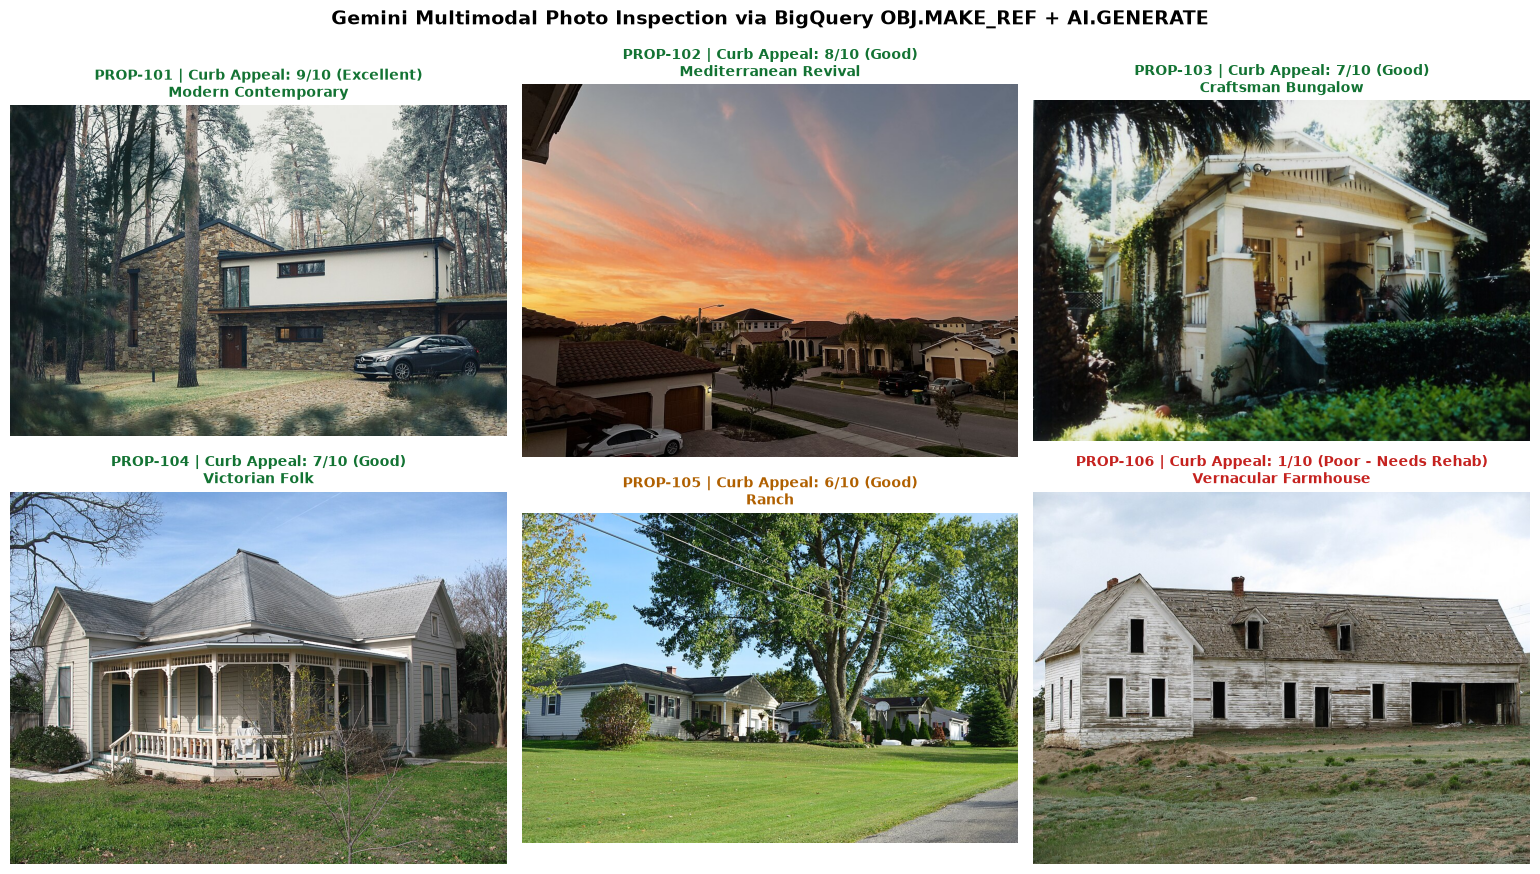

In [25]:
# Copyright 2026 Google LLC
# SPDX-License-Identifier: Apache-2.0

make_ref_expr = (
    f"OBJ.MAKE_REF(p.gcs_image_uri, '{CONNECTION_ID}')"
    if CONNECTION_ID
    else "OBJ.MAKE_REF(p.gcs_image_uri)"
)

photo_inspection_sql = f"""
CREATE OR REPLACE TABLE `{dataset_fqn}.property_photo_insights` AS
WITH refs AS (
  SELECT
    p.property_id,
    p.address,
    p.metro_area,
    p.list_price_usd,
    p.gcs_image_uri,
    OBJ.FETCH_METADATA({make_ref_expr}) AS image_ref
  FROM `{dataset_fqn}.properties` AS p
  WHERE p.gcs_image_uri IS NOT NULL
)
SELECT
  property_id,
  address,
  metro_area,
  list_price_usd,
  JSON_VALUE(image_ref.details, '$.gcs_metadata.content_type') AS content_type,
  ROUND(SAFE_CAST(JSON_VALUE(image_ref.details, '$.gcs_metadata.size') AS INT64) / 1024.0, 1) AS image_kb,
  (AI.GENERATE(
    (
      'You are a residential property appraiser. Inspect this exterior house photograph and extract the architectural style, exterior condition (Excellent, Good, Fair, or Poor - Needs Rehab), a curb appeal score from 1 (severely distressed) to 10 (luxury showcase), key visible exterior features, and a concise 1-sentence visual summary.',
      image_ref
    ),
    output_schema => 'architectural_style STRING, exterior_condition STRING, curb_appeal_score INT64, visible_features ARRAY<STRING>, photo_summary STRING'
  )).*
FROM refs
ORDER BY property_id
"""
print(photo_inspection_sql)

run_query(photo_inspection_sql, label="OBJ.MAKE_REF + Multimodal AI.GENERATE")
photo_insights_df = run_query(
    f"SELECT * FROM `{dataset_fqn}.property_photo_insights` ORDER BY property_id",
    label="Read property_photo_insights",
)
display(photo_insights_df[[
    "property_id", "metro_area", "image_kb", "architectural_style",
    "exterior_condition", "curb_appeal_score", "photo_summary"
]])

# Render the 6 real photos annotated with Gemini's extracted curb_appeal_score & condition
insights_by_id = photo_insights_df.set_index("property_id").to_dict("index")
fig, axes = plt.subplots(2, 3, figsize=(15.5, 9))
for ax, item in zip(axes.flat, REAL_PROPERTY_PHOTOS):
    pid = item["property_id"]
    img = Image.open(LOCAL_IMG_DIR / item["filename"]).convert("RGB")
    info = insights_by_id.get(pid, {})
    raw_score = info.get("curb_appeal_score")
    score_val = int(raw_score) if pd.notna(raw_score) else 0
    cond = info.get("exterior_condition", "Unknown")
    style = info.get("architectural_style", "Residential")
    badge_color = "#137333" if score_val >= 7 else ("#b06000" if score_val >= 5 else "#c5221f")
    ax.imshow(img)
    ax.set_title(
        f"{pid} | Curb Appeal: {score_val}/10 ({cond})\n{style}",
        fontsize=10,
        fontweight="bold",
        color=badge_color,
        pad=6,
    )
    ax.axis("off")
plt.suptitle("Gemini Multimodal Photo Inspection via BigQuery OBJ.MAKE_REF + AI.GENERATE", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

---
## Step 5: Semantic Listing Screening (`AI.IF`) & Buyer Segmentation (`AI.CLASSIFY`)

Next, we enrich our active `properties` table using BigQuery's managed semantic operators on `listing_notes`:
* **`AI.IF`**: Evaluates whether a listing is **move-in ready** (`is_move_in_ready BOOL`)—returning a native SQL boolean we can pass directly into `WHERE` clauses or downstream ML features!
* **`AI.CLASSIFY`**: Categorizes each home into one of four clean residential buyer segments (`Turnkey Family Home`, `Luxury Residence`, `Fixer-Upper / Value-Add`, `Starter / Cozy Home`).

> **🎙️ Live Demo Talk Track**
> *"Before `AI.IF` and `AI.CLASSIFY`, screening listing remarks meant maintaining brittle `REGEXP_CONTAINS` rules or parsing messy JSON strings from raw LLM calls. Now `AI.IF` returns a native `BOOL` (`is_move_in_ready`), and in Step 7 we'll pass `NOT is_move_in_ready AS is_fixer_upper` straight into `AI.PREDICT` so fixer-uppers are automatically valued against fixer-upper comps!"*

[AI.IF + AI.CLASSIFY] 0 rows returned in 14.00s (0.02 MB processed)
[Read properties_enriched] 25 rows returned in 3.94s (0.00 MB processed)


,property_id,metro_area,property_type,list_price_usd,is_move_in_ready,buyer_segment,listing_notes
0,PROP-101,"Denver, CO",Single-Family,985000.0,True,Luxury Residence,Custom contemporary stone-and-stucco foothills...
1,PROP-102,"Miami, FL",Single-Family,890000.0,True,Luxury Residence,Upscale Mediterranean residence with barrel-ti...
2,PROP-103,"Seattle, WA",Single-Family,825000.0,True,Turnkey Family Home,Well-maintained Craftsman single-family home f...
3,PROP-104,"Austin, TX",Cottage,515000.0,True,Starter / Cozy Home,Charming East Austin clapboard cottage with wr...
4,PROP-105,"Phoenix, AZ",Single-Family,465000.0,True,Turnkey Family Home,Move-in-ready suburban single-story ranch home...
5,PROP-106,"Austin, TX",Single-Family,335000.0,False,Fixer-Upper / Value-Add,Investor as-is fixer-upper needing full roof s...
6,PROP-107,"Denver, CO",Single-Family,437300.0,False,Fixer-Upper / Value-Add,Value-add 3-bedroom fixer-upper sold as-is; re...
7,PROP-108,"Phoenix, AZ",Single-Family,587300.0,True,Turnkey Family Home,Clean move-in-ready 3-bedroom suburban family ...
8,PROP-109,"Seattle, WA",Single-Family,1716100.0,True,Luxury Residence,Custom luxury 5-bedroom residence featuring re...
9,PROP-110,"Austin, TX",Cottage,353300.0,True,Starter / Cozy Home,Cozy 3-bedroom cottage ideal for first-time bu...


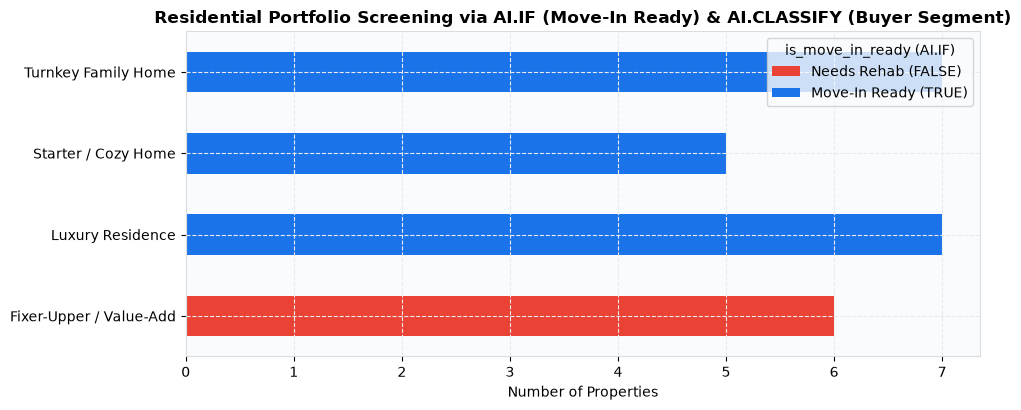

In [26]:
# Copyright 2026 Google LLC
# SPDX-License-Identifier: Apache-2.0

listing_triage_sql = f"""
CREATE OR REPLACE TABLE `{dataset_fqn}.properties_enriched` AS
WITH sample_props AS (
  SELECT *
  FROM `{dataset_fqn}.properties`
  ORDER BY gcs_image_uri IS NULL ASC, property_id ASC
  LIMIT {AI_SAMPLE_LIMIT}
)
SELECT
  p.property_id,
  p.address,
  p.metro_area,
  p.property_type,
  p.sqft,
  p.bedrooms,
  p.bathrooms,
  p.year_built,
  p.has_pool_or_view,
  p.list_price_usd,
  p.current_monthly_rent_usd,
  p.listing_notes,
  p.gcs_image_uri,
  AI.IF(
    (
      'Is this residential property move-in ready without needing major roof, siding, structural, or as-is renovation repairs? Listing: ',
      p.listing_notes
    ),
    examples => [
      ('Updated 4-bedroom suburban home with solid roof, modern kitchen, and fenced yard.', TRUE),
      ('As-is investor fixer-upper needing roof replacement, siding repair, and interior rehab.', FALSE)
    ]
  ) AS is_move_in_ready,
  AI.CLASSIFY(
    p.listing_notes,
    categories => [
      ('Turnkey Family Home', 'Move-in-ready 3+ bedroom suburban family residence in good condition'),
      ('Luxury Residence', 'Upscale custom home with pool, scenic view, or luxury architectural finishes'),
      ('Fixer-Upper / Value-Add', 'Older or distressed as-is property requiring roof, siding, or interior renovation'),
      ('Starter / Cozy Home', 'Compact townhome or cottage suited for entry-level or cozy low-maintenance living')
    ]
  ) AS buyer_segment
FROM sample_props AS p
"""

run_query(listing_triage_sql, label="AI.IF + AI.CLASSIFY")
enriched_df = run_query(
    f"""
    SELECT property_id, metro_area, property_type, list_price_usd, is_move_in_ready, buyer_segment, listing_notes
    FROM `{dataset_fqn}.properties_enriched`
    ORDER BY property_id
    """,
    label="Read properties_enriched",
)
display(enriched_df.head(10))

# Plot segment counts & move-in-ready split
seg_summary = (
    enriched_df.groupby(["buyer_segment", "is_move_in_ready"])
    .size()
    .unstack(fill_value=0)
)
ax = seg_summary.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 4.2),
    color={True: "#1a73e8", False: "#ea4335"},
)
ax.set_title("Residential Portfolio Screening via AI.IF (Move-In Ready) & AI.CLASSIFY (Buyer Segment)", fontweight="bold")
ax.set_xlabel("Number of Properties")
ax.set_ylabel("")
ax.legend(title="is_move_in_ready (AI.IF)", labels=["Needs Rehab (FALSE)", "Move-In Ready (TRUE)"])
plt.tight_layout()
plt.show()

---
## Step 6: Metro Sold Price & Rent Forecasting (`AI.FORECAST` — TimesFM)

Using our 2nd table, **`sold_and_rent_history`** (`72` months × `5` metros), we forecast the next **12 months** of both **`median_sold_price_usd`** and **`avg_monthly_rent_usd`** using BigQuery's built-in **TimesFM** time-series foundation model:
1. First, we validate accuracy on a 12-month holdout (`2025`) with **`AI.EVALUATE`** (`mean_absolute_percentage_error`, `mean_absolute_error`).
2. Next, we project 2026 metro sold prices and rents with **`AI.FORECAST`** (`id_cols => ['metro_area']`, `horizon => 12`, `confidence_level => 0.95`, `output_historical_time_series => TRUE`), pivoting `time_series_type` (`'history'` vs `'forecast'`) into a unified historical + forecast table.

> **🎙️ Live Demo Talk Track**
> *"With `AI.FORECAST`, we don't fit 5 separate ARIMA models for sold prices and another 5 for monthly rents. First, `AI.EVALUATE` verifies **TimesFM** achieves ~`1.4%`–`2%` MAPE on our 2025 holdout window. Then a single SQL query passes `id_cols => ['metro_area']` and `output_historical_time_series => TRUE` to forecast 12 months of sold prices and rents with 95% confidence bands in under 5 seconds."*

[AI.EVALUATE (TimesFM Backtest)] 5 rows returned in 1.56s (0.00 MB processed)


,metro_area,mape_pct,mae_usd
0,"Phoenix, AZ",1.40,6742.0
1,"Miami, FL",1.44,10536.0
2,"Denver, CO",1.85,11395.0
3,"Austin, TX",2.08,11521.0
4,"Seattle, WA",2.18,18139.0


[AI.FORECAST (Sold Price + Rent)] 0 rows returned in 4.83s (0.01 MB processed)
[Read metro_12m_forecasts] 420 rows returned in 1.68s (0.02 MB processed)
[12-Month Metro Appreciation Summary] 5 rows returned in 1.82s (0.01 MB processed)


,metro_area,current_median_sold_usd,forecast_12m_sold_usd,projected_price_growth_pct,current_avg_rent_usd,forecast_12m_rent_usd,projected_rent_growth_pct
0,"Miami, FL",730724.0,747685.0,2.32,3832.0,3919.0,2.27
1,"Phoenix, AZ",475454.0,488768.0,2.80,2472.0,2528.0,2.26
2,"Austin, TX",541425.0,553445.0,2.22,2757.0,2804.0,1.71
3,"Seattle, WA",824130.0,852639.0,3.46,3829.0,3885.0,1.46
4,"Denver, CO",612699.0,627293.0,2.38,2991.0,3035.0,1.46


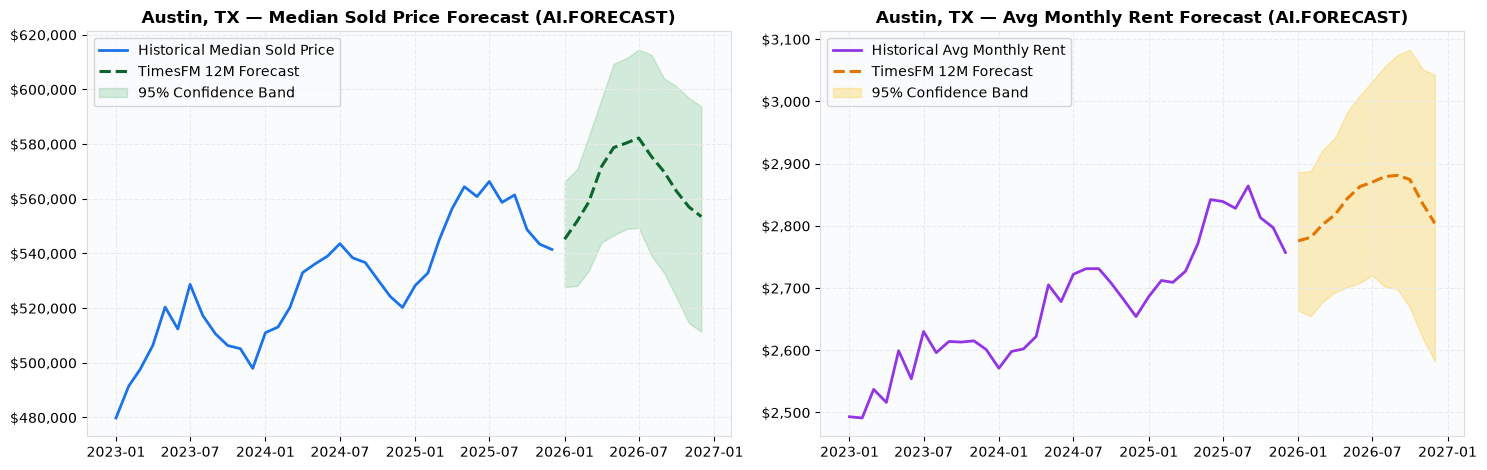

In [35]:
# Copyright 2026 Google LLC
# SPDX-License-Identifier: Apache-2.0

# 1) Backtest TimesFM on 2025 holdout with AI.EVALUATE
forecast_eval_df = run_query(
    f"""
    SELECT
      metro_area,
      ROUND(mean_absolute_percentage_error, 2) AS mape_pct,
      ROUND(mean_absolute_error, 0) AS mae_usd
    FROM AI.EVALUATE(
      (SELECT month_date, metro_area, median_sold_price_usd
       FROM `{dataset_fqn}.sold_and_rent_history`
       WHERE month_date < DATE '2025-01-01'),
      (SELECT month_date, metro_area, median_sold_price_usd
       FROM `{dataset_fqn}.sold_and_rent_history`
       WHERE month_date >= DATE '2025-01-01'),
      data_col => 'median_sold_price_usd',
      timestamp_col => 'month_date',
      id_cols => ['metro_area'],
      horizon => 12
    )
    ORDER BY mape_pct ASC
    """,
    label="AI.EVALUATE (TimesFM Backtest)",
)
display(forecast_eval_df)

# 2) Forecast 12 months ahead for BOTH median_sold_price_usd and avg_monthly_rent_usd using AI.FORECAST schema
forecast_sql = f"""
CREATE OR REPLACE TABLE `{dataset_fqn}.metro_12m_forecasts` AS
WITH sold_fc AS (
  SELECT
    metro_area,
    DATE(time_series_timestamp) AS month_date,
    IF(time_series_type = 'history', time_series_data, NULL) AS hist_sold_price_usd,
    IF(time_series_type = 'forecast', time_series_data, NULL) AS fc_sold_price_usd,
    prediction_interval_lower_bound AS sold_lower_usd,
    prediction_interval_upper_bound AS sold_upper_usd
  FROM AI.FORECAST(
    TABLE `{dataset_fqn}.sold_and_rent_history`,
    data_col => 'median_sold_price_usd',
    timestamp_col => 'month_date',
    id_cols => ['metro_area'],
    horizon => 12,
    confidence_level => 0.95,
    output_historical_time_series => TRUE
  )
),
rent_fc AS (
  SELECT
    metro_area,
    DATE(time_series_timestamp) AS month_date,
    IF(time_series_type = 'history', time_series_data, NULL) AS hist_rent_usd,
    IF(time_series_type = 'forecast', time_series_data, NULL) AS fc_rent_usd,
    prediction_interval_lower_bound AS rent_lower_usd,
    prediction_interval_upper_bound AS rent_upper_usd
  FROM AI.FORECAST(
    TABLE `{dataset_fqn}.sold_and_rent_history`,
    data_col => 'avg_monthly_rent_usd',
    timestamp_col => 'month_date',
    id_cols => ['metro_area'],
    horizon => 12,
    confidence_level => 0.95,
    output_historical_time_series => TRUE
  )
)
SELECT
  s.metro_area,
  s.month_date,
  MAX(s.hist_sold_price_usd) AS hist_sold_price_usd,
  MAX(s.fc_sold_price_usd) AS fc_sold_price_usd,
  MAX(s.sold_lower_usd) AS sold_lower_usd,
  MAX(s.sold_upper_usd) AS sold_upper_usd,
  MAX(r.hist_rent_usd) AS hist_rent_usd,
  MAX(r.fc_rent_usd) AS fc_rent_usd,
  MAX(r.rent_lower_usd) AS rent_lower_usd,
  MAX(r.rent_upper_usd) AS rent_upper_usd
FROM sold_fc AS s
JOIN rent_fc AS r
  USING (metro_area, month_date)
GROUP BY metro_area, month_date
ORDER BY metro_area, month_date
"""

run_query(forecast_sql, label="AI.FORECAST (Sold Price + Rent)")
fc_all_df = run_query(
    f"SELECT * FROM `{dataset_fqn}.metro_12m_forecasts` ORDER BY metro_area, month_date",
    label="Read metro_12m_forecasts",
)

# Summarize 12-month projected YoY appreciation by metro
yoy_summary_df = run_query(
    f"""
    WITH latest_hist AS (
      SELECT metro_area, median_sold_price_usd AS dec_2025_sold_usd, avg_monthly_rent_usd AS dec_2025_rent_usd
      FROM `{dataset_fqn}.sold_and_rent_history`
      WHERE month_date = DATE '2025-12-01'
    ),
    end_fc AS (
      SELECT metro_area, fc_sold_price_usd AS dec_2026_sold_usd, fc_rent_usd AS dec_2026_rent_usd
      FROM `{dataset_fqn}.metro_12m_forecasts`
      WHERE month_date = DATE '2026-12-01'
    )
    SELECT
      h.metro_area,
      ROUND(h.dec_2025_sold_usd, 0) AS current_median_sold_usd,
      ROUND(f.dec_2026_sold_usd, 0) AS forecast_12m_sold_usd,
      ROUND(100.0 * (f.dec_2026_sold_usd - h.dec_2025_sold_usd) / h.dec_2025_sold_usd, 2) AS projected_price_growth_pct,
      ROUND(h.dec_2025_rent_usd, 0) AS current_avg_rent_usd,
      ROUND(f.dec_2026_rent_usd, 0) AS forecast_12m_rent_usd,
      ROUND(100.0 * (f.dec_2026_rent_usd - h.dec_2025_rent_usd) / h.dec_2025_rent_usd, 2) AS projected_rent_growth_pct
    FROM latest_hist AS h
    JOIN end_fc AS f USING (metro_area)
    ORDER BY projected_rent_growth_pct DESC
    """,
    label="12-Month Metro Appreciation Summary",
)
display(yoy_summary_df)

# Plot two-panel fan chart (Median Sold Price + Avg Monthly Rent) for Austin, TX
focus_metro = "Austin, TX"
m_df = fc_all_df[fc_all_df["metro_area"] == focus_metro].copy()
m_df["month_date"] = pd.to_datetime(m_df["month_date"])
hist_part = m_df[m_df["hist_sold_price_usd"].notna() & (m_df["month_date"] >= "2023-01-01")]
fc_part = m_df[m_df["fc_sold_price_usd"].notna()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))
ax1.plot(hist_part["month_date"], hist_part["hist_sold_price_usd"], label="Historical Median Sold Price", color="#1a73e8", lw=2)
ax1.plot(fc_part["month_date"], fc_part["fc_sold_price_usd"], label="TimesFM 12M Forecast", color="#0d652d", lw=2.2, ls="--")
ax1.fill_between(fc_part["month_date"], fc_part["sold_lower_usd"], fc_part["sold_upper_usd"], color="#34a853", alpha=0.2, label="95% Confidence Band")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax1.set_title(f"{focus_metro} — Median Sold Price Forecast (AI.FORECAST)", fontweight="bold")
ax1.legend(loc="upper left")

ax2.plot(hist_part["month_date"], hist_part["hist_rent_usd"], label="Historical Avg Monthly Rent", color="#9334e6", lw=2)
ax2.plot(fc_part["month_date"], fc_part["fc_rent_usd"], label="TimesFM 12M Forecast", color="#e37400", lw=2.2, ls="--")
ax2.fill_between(fc_part["month_date"], fc_part["rent_lower_usd"], fc_part["rent_upper_usd"], color="#fbbc04", alpha=0.25, label="95% Confidence Band")
ax2.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax2.set_title(f"{focus_metro} — Avg Monthly Rent Forecast (AI.FORECAST)", fontweight="bold")
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()


---
## Step 7: Zero-Shot Comp Valuation (`AI.PREDICT` — TabFM, *Public Preview*)

Now we use our 3rd table, **`property_comps`**, to estimate fair-market **`sold_price_usd`** and **`monthly_rent_usd`** for our active homes in `properties_enriched` using **`AI.PREDICT`** (*Public Preview*, powered by Google's **TabFM** tabular foundation model):
1. First, we verify regression accuracy on our 50 `VALIDATION` comps via **`AI.EVALUATE`** (`mean_absolute_error`, `mean_squared_error`, `r2_score`).
2. Next, we run **`AI.PREDICT`** directly in SQL—passing `NOT is_move_in_ready AS is_fixer_upper` from Step 5 (`AI.IF`) so distressed properties like `PROP-106` are automatically priced against fixer-upper comps!

> **🎙️ Live Demo Talk Track (~60 sec while dual `AI.PREDICT` executes)**
> *"First, look at `AI.EVALUATE`—**TabFM** achieves a high $R^2$ score on our held-out validation comps in ~2 seconds with zero model training. Now, as this second query runs (~60 seconds because it executes two zero-shot TabFM passes—one predicting `sold_price_usd` and a second predicting `monthly_rent_usd`), notice what is **not** in our SQL: there is **no `CREATE MODEL` statement**, no feature encoding pipeline, and no endpoint to manage. `AI.PREDICT` feeds our 190 closed `TRAIN` comps as in-context tabular examples, and uses `NOT is_move_in_ready` from `AI.IF` so `PROP-106` is automatically valued as a fixer-upper rather than a turnkey home!"*

[AI.EVALUATE (TabFM Comps Holdout)] 2 rows returned in 2.21s (0.00 MB processed)


,target_column,mae_usd,mse_usd,r2_score
0,sold_price_usd,20298.0,590108028.0,0.9791
1,monthly_rent_usd,80.0,9889.0,0.9734


[AI.PREDICT (Sold Price + Monthly Rent)] 0 rows returned in 64.93s (0.02 MB processed)
[Read property_comp_valuations] 25 rows returned in 1.74s (0.00 MB processed)


,property_id,metro_area,buyer_segment,is_move_in_ready,list_price_usd,comp_predicted_sold_usd,comp_predicted_rent_usd,okf_effective_yield_pct
0,PROP-101,"Denver, CO",Luxury Residence,True,985000.0,1122300.0,4416.0,4.49
1,PROP-102,"Miami, FL",Luxury Residence,True,890000.0,1122300.0,4736.0,4.81
2,PROP-103,"Seattle, WA",Turnkey Family Home,True,825000.0,704512.0,2960.0,4.79
3,PROP-104,"Austin, TX",Starter / Cozy Home,True,515000.0,497664.0,2448.0,5.61
4,PROP-105,"Phoenix, AZ",Turnkey Family Home,True,465000.0,516096.0,2208.0,4.88
5,PROP-106,"Austin, TX",Fixer-Upper / Value-Add,False,335000.0,350208.0,2016.0,6.56
6,PROP-107,"Denver, CO",Fixer-Upper / Value-Add,False,437300.0,428032.0,2272.0,6.05
7,PROP-108,"Phoenix, AZ",Turnkey Family Home,True,587300.0,634880.0,2416.0,4.34
8,PROP-109,"Seattle, WA",Luxury Residence,True,1716100.0,1228800.0,4800.0,4.45
9,PROP-110,"Austin, TX",Starter / Cozy Home,True,353300.0,491520.0,2336.0,5.42


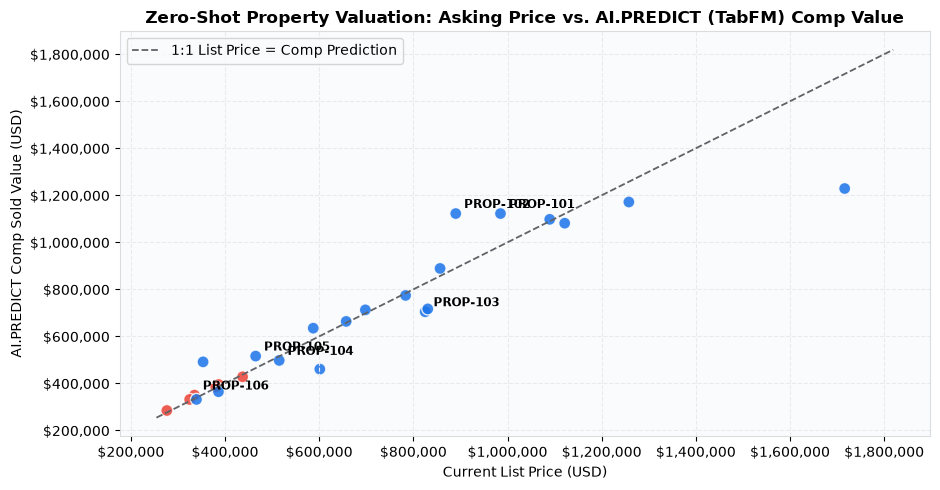

In [39]:
# Copyright 2026 Google LLC
# SPDX-License-Identifier: Apache-2.0

# 1) Evaluate TabFM zero-shot accuracy on held-out VALIDATION comps
comp_eval_df = run_query(
    f"""
    SELECT
      'sold_price_usd' AS target_column,
      ROUND(mean_absolute_error, 0) AS mae_usd,
      ROUND(mean_squared_error, 0) AS mse_usd,
      ROUND(r2_score, 4) AS r2_score
    FROM AI.EVALUATE(
      (SELECT metro_area, property_type, sqft, bedrooms, bathrooms, year_built, has_pool_or_view, is_fixer_upper, sold_price_usd
       FROM `{dataset_fqn}.property_comps` WHERE split_set = 'TRAIN'),
      (SELECT metro_area, property_type, sqft, bedrooms, bathrooms, year_built, has_pool_or_view, is_fixer_upper, sold_price_usd
       FROM `{dataset_fqn}.property_comps` WHERE split_set = 'VALIDATION'),
      label_col => 'sold_price_usd'
    )
    UNION ALL
    SELECT
      'monthly_rent_usd' AS target_column,
      ROUND(mean_absolute_error, 0) AS mae_usd,
      ROUND(mean_squared_error, 0) AS mse_usd,
      ROUND(r2_score, 4) AS r2_score
    FROM AI.EVALUATE(
      (SELECT metro_area, property_type, sqft, bedrooms, bathrooms, year_built, has_pool_or_view, is_fixer_upper, monthly_rent_usd
       FROM `{dataset_fqn}.property_comps` WHERE split_set = 'TRAIN'),
      (SELECT metro_area, property_type, sqft, bedrooms, bathrooms, year_built, has_pool_or_view, is_fixer_upper, monthly_rent_usd
       FROM `{dataset_fqn}.property_comps` WHERE split_set = 'VALIDATION'),
      label_col => 'monthly_rent_usd'
    )
    """,
    label="AI.EVALUATE (TabFM Comps Holdout)",
)
display(comp_eval_df)

# 2) Predict Fair-Market Sold Price & Monthly Rent for our active properties via AI.PREDICT
predict_comps_sql = f"""
CREATE OR REPLACE TABLE `{dataset_fqn}.property_comp_valuations` AS
WITH sold_preds AS (
  SELECT
    property_id,
    address,
    metro_area,
    property_type,
    sqft,
    bedrooms,
    bathrooms,
    year_built,
    is_move_in_ready,
    buyer_segment,
    list_price_usd,
    current_monthly_rent_usd,
    ROUND(predicted_sold_price_usd, 0) AS comp_predicted_sold_usd
  FROM AI.PREDICT(
    (SELECT metro_area, property_type, sqft, bedrooms, bathrooms, year_built, has_pool_or_view, is_fixer_upper, sold_price_usd
     FROM `{dataset_fqn}.property_comps` WHERE split_set = 'TRAIN'),
    (SELECT
       property_id, address, metro_area, property_type, sqft, bedrooms, bathrooms, year_built, has_pool_or_view,
       NOT is_move_in_ready AS is_fixer_upper,
       is_move_in_ready, buyer_segment, list_price_usd, current_monthly_rent_usd
     FROM `{dataset_fqn}.properties_enriched`),
    label_col => 'sold_price_usd'
  )
),
rent_preds AS (
  SELECT
    property_id,
    ROUND(predicted_monthly_rent_usd, 0) AS comp_predicted_rent_usd
  FROM AI.PREDICT(
    (SELECT metro_area, property_type, sqft, bedrooms, bathrooms, year_built, has_pool_or_view, is_fixer_upper, monthly_rent_usd
     FROM `{dataset_fqn}.property_comps` WHERE split_set = 'TRAIN'),
    (SELECT
       property_id, metro_area, property_type, sqft, bedrooms, bathrooms, year_built, has_pool_or_view,
       NOT is_move_in_ready AS is_fixer_upper
     FROM `{dataset_fqn}.properties_enriched`),
    label_col => 'monthly_rent_usd'
  )
)
SELECT
  s.*,
  r.comp_predicted_rent_usd,
  ROUND(s.comp_predicted_sold_usd - s.list_price_usd, 0) AS estimated_equity_spread_usd,
  ROUND(100.0 * SAFE_DIVIDE(12.0 * r.comp_predicted_rent_usd * 0.95, s.comp_predicted_sold_usd), 2) AS okf_effective_yield_pct
FROM sold_preds AS s
JOIN rent_preds AS r USING (property_id)
ORDER BY property_id
"""

run_query(predict_comps_sql, label="AI.PREDICT (Sold Price + Monthly Rent)")
valuations_df = run_query(
    f"SELECT * FROM `{dataset_fqn}.property_comp_valuations` ORDER BY property_id",
    label="Read property_comp_valuations",
)
display(valuations_df[[
    "property_id", "metro_area", "buyer_segment", "is_move_in_ready",
    "list_price_usd", "comp_predicted_sold_usd", "comp_predicted_rent_usd", "okf_effective_yield_pct"
]].head(10))

# Plot Asking List Price vs TabFM Comp Predicted Price
fig, ax = plt.subplots(figsize=(9.5, 5))
colors = valuations_df["is_move_in_ready"].map({True: "#1a73e8", False: "#ea4335"})
ax.scatter(
    valuations_df["list_price_usd"],
    valuations_df["comp_predicted_sold_usd"],
    c=colors,
    s=75,
    alpha=0.85,
    edgecolors="white",
)
lims = [
    min(valuations_df["list_price_usd"].min(), valuations_df["comp_predicted_sold_usd"].min()) * 0.92,
    max(valuations_df["list_price_usd"].max(), valuations_df["comp_predicted_sold_usd"].max()) * 1.06,
]
ax.plot(lims, lims, "--", color="#5f6368", lw=1.3, label="1:1 List Price = Comp Prediction")
for _, r in valuations_df[valuations_df["property_id"].isin([p["property_id"] for p in REAL_PROPERTY_PHOTOS])].iterrows():
    ax.annotate(
        r["property_id"],
        (r["list_price_usd"], r["comp_predicted_sold_usd"]),
        xytext=(6, 4),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold",
    )
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("Current List Price (USD)")
ax.set_ylabel("AI.PREDICT Comp Sold Value (USD)")
ax.set_title("Zero-Shot Property Valuation: Asking Price vs. AI.PREDICT (TabFM) Comp Value", fontweight="bold")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

---
## Step 8: Unified Multimodal Property Valuation Cards (`AI.GENERATE`)

Finally, we join all four signals for our 6 pictured properties—**Real Photo Inspection (`OBJ.MAKE_REF` + `AI.GENERATE`)**, **Listing Screening (`AI.IF` + `AI.CLASSIFY`)**, **12-Month Metro Forecast (`AI.FORECAST`)**, and **Comp Sold & Rent Valuation (`AI.PREDICT`)**—to generate a concise 2-sentence **Property Valuation & Investment Card** right inside BigQuery.

> **🎙️ Live Demo Talk Track**
> *"Notice how everything comes together in one standard SQL `JOIN` (~5 seconds): visual curb appeal and exterior condition from real Cloud Storage photos, buyer segment from `AI.CLASSIFY`, 12-month metro appreciation from `AI.FORECAST`, and comp-backed price, rent, and vacancy-adjusted rental yield from `AI.PREDICT`. Gemini synthesizes all four signals into a structured `[recommendation_tag]` and a crisp 2-sentence valuation brief per property."*

In [41]:
# Copyright 2026 Google LLC
# SPDX-License-Identifier: Apache-2.0

valuation_cards_sql = f"""
WITH metro_growth AS (
  SELECT
    h.metro_area,
    ROUND(100.0 * (f.fc_sold_price_usd - h.median_sold_price_usd) / h.median_sold_price_usd, 1) AS metro_12m_price_growth_pct,
    ROUND(100.0 * (f.fc_rent_usd - h.avg_monthly_rent_usd) / h.avg_monthly_rent_usd, 1) AS metro_12m_rent_growth_pct
  FROM `{dataset_fqn}.sold_and_rent_history` AS h
  JOIN `{dataset_fqn}.metro_12m_forecasts` AS f
    ON h.metro_area = f.metro_area AND f.month_date = DATE '2026-12-01'
  WHERE h.month_date = DATE '2025-12-01'
)
SELECT
  v.property_id,
  v.address,
  v.buyer_segment,
  img.exterior_condition,
  img.curb_appeal_score,
  v.list_price_usd,
  v.comp_predicted_sold_usd,
  v.comp_predicted_rent_usd,
  v.okf_effective_yield_pct,
  g.metro_12m_price_growth_pct,
  (AI.GENERATE(
    CONCAT(
      'Write a crisp 2-sentence residential valuation brief for a property analyst. ',
      'Property ', v.property_id, ' (', v.address, ') is classified as ', v.buyer_segment,
      ' with exterior photo condition "', img.exterior_condition, '" (curb appeal ', CAST(img.curb_appeal_score AS STRING), '/10: ', img.photo_summary, '). ',
      'List price is $', CAST(CAST(v.list_price_usd AS INT64) AS STRING),
      ' vs AI.PREDICT comp value $', CAST(CAST(v.comp_predicted_sold_usd AS INT64) AS STRING),
      ' and predicted rent $', CAST(CAST(v.comp_predicted_rent_usd AS INT64) AS STRING), '/mo ',
      '(OKF Effective Gross Rental Yield: ', CAST(v.okf_effective_yield_pct AS STRING), '%), ',
      'with metro 12-month price growth forecast at ', CAST(g.metro_12m_price_growth_pct AS STRING), '%.'
    ),
    output_schema => 'recommendation_tag STRING, analyst_valuation_brief STRING'
  )).*
FROM `{dataset_fqn}.property_comp_valuations` AS v
JOIN `{dataset_fqn}.property_photo_insights` AS img USING (property_id)
JOIN metro_growth AS g ON v.metro_area = g.metro_area
ORDER BY v.property_id
"""

cards_df = run_query(valuation_cards_sql, label="Final Property Valuation Cards")
display(cards_df[[
    "property_id", "buyer_segment", "curb_appeal_score", "list_price_usd",
    "comp_predicted_sold_usd", "comp_predicted_rent_usd", "okf_effective_yield_pct", "recommendation_tag"
]])

for _, row in cards_df.iterrows():
    print(f"\n🏠 {row['property_id']} — {row['address']} [{row['recommendation_tag']}]")
    print(f"   {row['analyst_valuation_brief']}")

[Final Property Valuation Cards] 6 rows returned in 5.18s (0.01 MB processed)


,property_id,buyer_segment,curb_appeal_score,list_price_usd,comp_predicted_sold_usd,comp_predicted_rent_usd,okf_effective_yield_pct,recommendation_tag
0,PROP-101,Luxury Residence,9,985000.0,1122300.0,4416.0,4.49,Strong Buy
1,PROP-102,Luxury Residence,8,890000.0,1122300.0,4736.0,4.81,Strong Buy
2,PROP-103,Turnkey Family Home,7,825000.0,704512.0,2960.0,4.79,Overvalued
3,PROP-104,Starter / Cozy Home,7,515000.0,497664.0,2448.0,5.61,Caution
4,PROP-105,Turnkey Family Home,6,465000.0,516096.0,2208.0,4.88,Strong Buy
5,PROP-106,Fixer-Upper / Value-Add,1,335000.0,350208.0,2016.0,6.56,Speculative Value-Add



🏠 PROP-101 — 418 Pine Ridge Trail, Denver, CO [Strong Buy]
   Property PROP-101 presents a compelling value opportunity, listed at $985,000 against an AI-predicted valuation of $1,122,300 supported by excellent modern curb appeal and a steady 2.4% metro growth forecast. The asset delivers an effective gross rental yield of 4.49% with a projected monthly rent of $4,416, making it an attractive target for capital appreciation and cash flow.

🏠 PROP-102 — 742 Palm Harbor Way, Miami, FL [Strong Buy]
   Property PROP-102 presents a compelling upside with a list price of $890,000 against an AI-predicted value of $1,122,300 and a solid rental yield of 4.81%. Backed by strong Mediterranean curb appeal in good condition and a 2.3% metro appreciation forecast, this luxury residence offers significant value.

🏠 PROP-103 — 964 Cedar Crest Ave, Seattle, WA [Overvalued]
   Property PROP-103 is a charming Craftsman bungalow listed at $825,000, significantly exceeding the AI predicted value of $704,5

---
## Step 9: Architecture Takeaways & Automated Demo Cleanup

### Key Takeaways from This Simplified 3-Table Demo
1. **Simple Data Model, Full Multimodal Depth**: With just **`properties`**, **`sold_and_rent_history`**, **`property_comps`**, and **real Cloud Storage photos**, BigQuery handles visual inspection, semantic text screening, time-series forecasting, and comp valuation in standard GoogleSQL.
2. **Zero Training Pipelines to Maintain**: **`AI.FORECAST` (TimesFM)** and **`AI.PREDICT` (TabFM)** deliver instant projections and comp estimates directly over BigQuery tables without managing custom training jobs or serving endpoints.
3. **Optional Portable Governance (`OKF v0.2`)**: Storing semantic definitions in `gs://<BUCKET>/property_okf/` keeps KPI formulas and exclusions consistent across analysts and AI agents.

> **🎙️ Presenter Closing & Cleanup Talk Track**
> *"That completes our end-to-end property trend and valuation workflow in BigQuery—zero data movement outside GoogleSQL and Cloud Storage. Because `RUN_CLEANUP` is enabled below, the final cell automatically removes our demo BigQuery dataset (`cotality_property`), staged property photos (`cotality_property_demo/images/`), and optional `property_okf/` objects while keeping the shared `cotality-workshop` bucket intact so this notebook can be re-run cleanly anytime."*

In [ ]:
# Copyright 2026 Google LLC
# SPDX-License-Identifier: Apache-2.0

# @title Automated Demo Cleanup (Deletes BigQuery dataset + staged GCS images & property_okf) { display-mode: "form" }
RUN_CLEANUP = True  # @param {type:"boolean"}
CLEAN_LOCAL_CACHE = True  # @param {type:"boolean"}

if RUN_CLEANUP:
    # 1) Delete BigQuery demo dataset and all base/derived tables
    bq_client.delete_dataset(dataset_fqn, delete_contents=True, not_found_ok=True)
    print(f"Deleted BigQuery dataset `{dataset_fqn}` (and all demo tables).")

    # 2) Delete staged property photographs in Cloud Storage (preserving the bucket itself)
    img_blobs = list(bucket.list_blobs(prefix="cotality_property_demo/"))
    for b in img_blobs:
        b.delete()
    print(f"Deleted {len(img_blobs)} staged image object(s) under `gs://{BUCKET_NAME}/cotality_property_demo/`.")

    # 3) Delete optional Open Knowledge Format (OKF) bundle in Cloud Storage
    okf_blobs = list(bucket.list_blobs(prefix="property_okf/"))
    for b in okf_blobs:
        b.delete()
    print(f"Deleted {len(okf_blobs)} OKF object(s) under `gs://{BUCKET_NAME}/property_okf/`.")

    # 4) Remove local runtime cache folders if requested
    if CLEAN_LOCAL_CACHE:
        import shutil as _shutil
        for local_dir in (pathlib.Path("./property_images"), pathlib.Path("./property_okf"), pathlib.Path("./cotality_simple_property_okf")):
            if local_dir.exists():
                _shutil.rmtree(local_dir, ignore_errors=True)
        print("Cleaned local runtime staging directories (`./property_images`, `./property_okf`).")

    print(f"Cleanup complete! Shared bucket `gs://{BUCKET_NAME}` was preserved intact.")
else:
    print("Cleanup skipped (RUN_CLEANUP = False). Demo dataset, photos, and `property_okf/` remain available for Q&A.")